# $\color{#dda}{\text{Examen 1: RapidoMX Delivery Analytics}}$

**Regression Analysis · Ingeniería en Ciencia de Datos · ITESO** · Prof. María Elisa Vaca Gómez

**Alumne:** Lambda Remiel Heredia Pérez

**Datos:** `rapidomx_pedidos.csv` (4,080 filas, 14 variables, una fila por pedido entregado en la CDMX)

**Estructura:** bitácora de decisiones · Parte 1 limpieza y exploración · Parte 2 Operaciones (regresión lineal múltiple) · Parte 3 Director Regional (ANOVA) · Parte 4 Experiencia del Cliente (regresión logística) · Parte 5 memo ejecutivo.

**Convenciones en todo el notebook:** α = 0.05; categorías de referencia `zona = Norte`, `tipo_vehiculo = Moto`, `franja_horaria = Mañana`, `clima = Despejado`; partición 70 % entrenamiento / 30 % prueba con `random_state=42`.

---
# $\color{#dda}{\text{Bitácora de decisiones}}$

| # | Decisión | Alternativas consideradas | Por qué elegí esta |
|---|---|---|---|
| 1 | Eliminar 80 filas duplicadas (mismo `id_pedido` y mismos valores en las 14 columnas). | Conservarlas. | Es el mismo pedido registrado dos veces. Conservarlo le da doble peso y reduce artificialmente los errores estándar. |
| 2 | Unificar etiquetas: `zona` tenía 13 variantes (espacios, mayúsculas) y `tipo_vehiculo` 9 (`moto`, `Motocicleta`, `bici`, `Automóvil`…). Se normalizan a 4 zonas y 3 vehículos. | Borrar las filas con etiquetas raras; tratarlas como categorías distintas. | Son errores de captura, no categorías nuevas. El significado es inequívoco, así que corregir no inventa información y evita perder 431 pedidos (11 % de la base). |
| 3 | Eliminar 40 pedidos con `tiempo_entrega_min` = 0, 720 o 999. | Imputar con la mediana o con una predicción; recortar (winsorizar). | Son códigos del sistema: 0 = no registrado, 720 = exactamente 12 h, 999 = código de error. Hay un hueco entre 91.8 y 720 min sin ningún dato real. Es la variable respuesta: imputarla sería inventar justo lo que queremos explicar. |
| 4 | Eliminar 80 pedidos sin `clima` y 158 sin `experiencia_repartidor_meses` (6.4 % de la base). | Imputar mediana/moda; crear la categoría "Desconocido". | Las pruebas de la Parte 1 no muestran diferencia en la tasa de mala experiencia entre pedidos con y sin dato, y la experiencia faltante no cambia el tiempo medio. Imputar el clima sería adivinar una variable que mueve ~6 min la entrega. Con 3,726 pedidos restantes la potencia sobra. |
| 5 | Conservar los 3 pedidos con `distancia_km` = 18.0 (posible tope del sistema). | Eliminarlos. | Su tiempo de entrega (76–85 min) es coherente con la distancia; no distorsionan el modelo. |
| 6 | Partición 70/30 (`random_state=42`) solo para los modelos predictivos (Partes 2 y 4). El ANOVA y la comparación de la Parte 3 usan la base limpia completa. | Hacer el ANOVA solo en entrenamiento. | El ANOVA es inferencia, no predicción: no hay nada que evaluar fuera de muestra y con más datos la prueba es más precisa. |
| 7 | Parte 2: excluir `pedido_con_error` y `calificacion_cliente` como predictores del tiempo. | Incluir todo. | Ocurren *después* de la entrega; no pueden causar el tiempo de entrega y no existen cuando se le promete un tiempo al cliente. |
| 8 | Parte 2: excluir `monto_pedido_mxn` y `cliente_nuevo` del modelo final. | Mantenerlas; selección stepwise. | F parcial conjunta p = 0.91: no aportan nada una vez que están los demás factores, y no hay un mecanismo operativo por el que el monto o la novedad del cliente retrasen al repartidor. |
| 9 | Parte 2: no incluir la interacción distancia × vehículo. | Incluirla. | F parcial p = 0.23: el costo por km es el mismo en moto, auto o bici; el vehículo solo suma un tiempo fijo. Modelo más simple, misma precisión. |
| 10 | Parte 2: ante la heterocedasticidad, reportar errores estándar robustos HC3 y dar un margen de error distinto con lluvia y sin lluvia. | Transformar con logaritmo; mínimos cuadrados ponderados. | Los coeficientes de MCO siguen siendo insesgados; HC3 corrige los p-values. El logaritmo haría que cada factor se lea en % y no en minutos, que es lo que pidió Operaciones. |
| 11 | Parte 3: ANOVA de una vía + Tukey HSD (visto en clase), con Welch y Kruskal-Wallis como pruebas de robustez. | Solo ANOVA clásico; Games-Howell. | Levene rechaza varianzas iguales y los residuos no son normales; Welch y Kruskal-Wallis no dependen de esos supuestos y confirman (o no) la conclusión. |
| 12 | Parte 4: dos modelos logísticos. Uno **explicativo** (incluye tiempo de entrega y error en el pedido) para entender causas, y uno **operativo** con solo lo que se conoce al momento de hacer el pedido, para mandar cupones. | Un solo modelo con todas las variables. | El tiempo de entrega, el error y la calificación no existen cuando se coloca el pedido. Un modelo que los usa se ve mejor en papel pero no se puede usar para el cupón (fuga de información). |
| 13 | Supuesto: el vehículo y la experiencia del repartidor se conocen al momento del pedido (el repartidor se asigna al aceptarlo). | Excluirlos del modelo operativo. | La app asigna repartidor al aceptar el pedido; si en la práctica se asigna después, el cupón se mandaría en ese momento. Se reporta como limitación. |
| 14 | Parte 4: umbral de clasificación 0.29 (índice de Youden) en vez de 0.50. | Umbral 0.50; mandar cupón al 10 % o 20 % más riesgoso. | Con 0.50 el modelo solo detecta 1 de cada 3 malas experiencias. La tasa base es 25 %, así que 0.50 es demasiado exigente. Se muestra también la opción por deciles si el presupuesto es menor. |
| 15 | Parte 4: mantener `franja_horaria` en el modelo operativo aunque su prueba conjunta no sea significativa (p = 0.12). Quitar `monto_pedido_mxn` (LR p = 0.77). | Quitar también la franja. | La franja sí mueve el tiempo de entrega (Parte 2) y Comida queda en el límite (p = 0.052); quitarla no cambia las demás conclusiones. El monto no tiene efecto ni explicación operativa. |

---
# $\color{#dda}{\text{Parte 1. Preparación y exploración de datos}}$

## $\color{#dda}{\text{1.1 Revisión de calidad}}$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error, mean_squared_error,
                             r2_score, confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, auc)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

TEAL, CORAL, GREY, GOLD = "#0F7173", "#D9622B", "#5C6B70", "#C9A227"
ZONAS = ["Norte", "Centro", "Sur", "Periferia"]
ZONA_COLORES = dict(zip(ZONAS, [TEAL, CORAL, GOLD, GREY]))
ALPHA = 0.05

In [2]:
raw = pd.read_csv("rapidomx_pedidos.csv", encoding="utf-8")
print(f"Filas: {raw.shape[0]:,}   Columnas: {raw.shape[1]}")
raw.head()

Filas: 4,080   Columnas: 14


,id_pedido,zona,franja_horaria,clima,distancia_km,pedidos_activos_zona,tipo_vehiculo,experiencia_repartidor_meses,tiempo_preparacion_min,monto_pedido_mxn,cliente_nuevo,tiempo_entrega_min,pedido_con_error,calificacion_cliente
0,RMX-03590,Centro,Comida,Despejado,1.60,12,Bicicleta,35.0,16.5,496.0,0,49.8,0,1
1,RMX-03951,Centro,Noche,Despejado,1.05,10,Auto,26.0,18.5,918.0,0,34.6,0,4
2,RMX-03583,Norte,Noche,Despejado,7.28,7,Moto,57.0,16.9,240.0,0,52.5,0,3
3,RMX-01870,Sur,Tarde,Despejado,3.35,10,Moto,10.0,19.8,560.0,0,40.1,0,4
4,RMX-00961,Sur,Tarde,Despejado,4.04,7,Moto,32.0,10.1,513.0,0,28.6,0,4


In [3]:
print("Valores nulos por columna:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nFilas completamente duplicadas:", raw.duplicated().sum())
print("id_pedido repetidos:          ", raw["id_pedido"].duplicated().sum())
print("Duplicados ignorando id_pedido:", raw.drop(columns="id_pedido").duplicated().sum())

Valores nulos por columna:
clima                            80
experiencia_repartidor_meses    163
dtype: int64

Filas completamente duplicadas: 80
id_pedido repetidos:           80
Duplicados ignorando id_pedido: 80


**Interpretación.** Hay 80 filas que son copia exacta de otra (mismo `id_pedido` y mismos valores): el sistema registró dos veces el mismo pedido. Además faltan 80 valores de `clima` y 163 de `experiencia_repartidor_meses`.

In [4]:
for col in ["zona", "franja_horaria", "clima", "tipo_vehiculo"]:
    print(f"--- {col} ---")
    print(raw[col].map(repr).value_counts(dropna=False).to_string())
    print()

--- zona ---
zona
'Centro'        1108
'Sur'            992
'Norte'          974
'Periferia'      762
'NORTE'           36
' Sur'            35
'CENTRO'          31
'periferia'       29
'centro'          29
'Centro '         25
'sur'             24
'norte'           23
'Periferia '      12

--- franja_horaria ---
franja_horaria
'Comida'    1417
'Noche'     1262
'Tarde'      816
'Mañana'     585

--- clima ---
clima
'Despejado'    3178
'Lluvia'        822
nan              80

--- tipo_vehiculo ---
tipo_vehiculo
'Moto'           2498
'Auto'            727
'Bicicleta'       653
'moto'             69
'Motocicleta'      68
'bici'             19
'auto'             17
'bicicleta'        15
'Automóvil'        14



**Interpretación.** `zona` debería tener 4 valores y tiene 13: `'Centro '` con espacio al final, `' Sur'` con espacio al inicio, `NORTE`, `periferia`, etc. `tipo_vehiculo` mezcla `Moto`, `moto` y `Motocicleta`; `Auto`, `auto` y `Automóvil`; `Bicicleta`, `bicicleta` y `bici`. Si no se corrige, el modelo trataría `NORTE` y `Norte` como zonas distintas. `franja_horaria` está limpia.

In [5]:
num_cols = ["distancia_km", "pedidos_activos_zona", "experiencia_repartidor_meses",
            "tiempo_preparacion_min", "monto_pedido_mxn", "tiempo_entrega_min"]
raw[num_cols].describe(percentiles=[0.01, 0.5, 0.99]).T.round(2)

,count,mean,std,min,1%,50%,99%,max
distancia_km,4080.0,4.42,2.66,0.59,0.85,4.07,12.85,18.0
pedidos_activos_zona,4080.0,10.94,4.38,1.00,2.00,11.00,21.00,26.0
experiencia_repartidor_meses,3917.0,30.62,17.19,1.00,1.00,31.00,60.00,60.0
tiempo_preparacion_min,4080.0,14.95,3.94,5.00,5.70,14.90,24.20,26.7
monto_pedido_mxn,4080.0,351.38,169.68,80.00,108.00,318.50,907.42,1729.0
tiempo_entrega_min,4080.0,47.09,66.09,0.00,19.78,40.90,80.99,999.0


In [6]:
t = raw["tiempo_entrega_min"]
print("Valores de tiempo_entrega_min que más se repiten fuera de 10–150 min:")
print(t[(t < 10) | (t > 150)].value_counts().sort_index().to_string())
print("\nLos 5 valores válidos más bajos:", sorted(t[t > 0])[:5])
print("Los 5 valores válidos más altos:", sorted(t[t < 700])[-5:])
print("\nTope de distancia_km = 18.0:", (raw["distancia_km"] == 18).sum(), "pedidos")

Valores de tiempo_entrega_min que más se repiten fuera de 10–150 min:
tiempo_entrega_min
0.0      13
720.0    16
999.0    11

Los 5 valores válidos más bajos: [14.0, 14.5, 14.5, 14.8, 15.5]
Los 5 valores válidos más altos: [85.7, 88.4, 88.9, 90.4, 91.8]

Tope de distancia_km = 18.0: 3 pedidos


**Interpretación.** Todas las variables están en rangos físicamente posibles excepto `tiempo_entrega_min`: el percentil 99 es 81 min pero el máximo es 999. Los valores fuera de rango no son extremos naturales sino tres códigos que se repiten exactamente: **0 min** (13 pedidos: un pedido entregado no puede tardar cero), **720 min** (16 pedidos: exactamente 12 horas) y **999 min** (11 pedidos: el típico código de "sin dato"). Entre 91.8 y 720 min no hay ningún pedido, así que la frontera es clara. Los tiempos válidos más bajos (14 min) son razonables para entregas cortas con preparación rápida.

La distancia máxima (18.0 km) aparece 3 veces, lo que sugiere un tope del sistema, pero sus tiempos de entrega son coherentes con esa distancia, así que se conservan (bitácora #5).

## $\color{#dda}{\text{1.2 Limpieza}}$

In [7]:
df = raw.drop_duplicates().copy()
n0 = len(df)

# 1) Etiquetas: espacios sobrantes, mayúsculas y sinónimos
df["zona"] = df["zona"].str.strip().str.capitalize()
mapa_vehiculo = {"moto": "Moto", "motocicleta": "Moto", "auto": "Auto", "automóvil": "Auto",
                 "bici": "Bicicleta", "bicicleta": "Bicicleta"}
df["tipo_vehiculo"] = df["tipo_vehiculo"].str.strip().str.lower().map(mapa_vehiculo)
assert df["zona"].isin(ZONAS).all() and df["tipo_vehiculo"].notna().all()

# 2) Tiempos de entrega imposibles (códigos del sistema): 0, 720 y 999 minutos
invalido = df["tiempo_entrega_min"].isin([0, 720, 999])
print(f"Duplicados eliminados:            {raw.shape[0] - n0}")
print(f"Tiempos de entrega inválidos:     {invalido.sum()}")
df = df[~invalido]

# 3) Nulos en clima y experiencia: se revisa si son al azar antes de decidir
print(f"Nulos en clima:                   {df['clima'].isna().sum()}")
print(f"Nulos en experiencia:             {df['experiencia_repartidor_meses'].isna().sum()}")

Duplicados eliminados:            80
Tiempos de entrega inválidos:     40
Nulos en clima:                   80
Nulos en experiencia:             158


**¿Se pueden borrar los pedidos con datos faltantes sin sesgar el análisis?** Si los pedidos sin dato se parecen a los demás en lo que nos importa (tiempo de entrega y mala experiencia), borrarlos no cambia las conclusiones.

- **H₀:** el tiempo medio de entrega (o la proporción de malas experiencias) es igual entre pedidos con dato y sin dato.
- **H₁:** son distintos.

In [8]:
# ¿Los pedidos con dato faltante se parecen a los demás? Si sí, borrarlos no sesga.
for col in ["clima", "experiencia_repartidor_meses"]:
    falta = df[col].isna()
    t_stat, t_p = stats.ttest_ind(df.loc[falta, "tiempo_entrega_min"], df.loc[~falta, "tiempo_entrega_min"], equal_var=False)
    malo = df["calificacion_cliente"] <= 2
    chi2, chi_p, _, _ = stats.chi2_contingency(pd.crosstab(falta, malo))
    print(f"{col}: entrega media con dato {df.loc[~falta, 'tiempo_entrega_min'].mean():.1f} vs sin dato "
          f"{df.loc[falta, 'tiempo_entrega_min'].mean():.1f} min (Welch t p = {t_p:.3f}); "
          f"% mala experiencia {malo[~falta].mean():.1%} vs {malo[falta].mean():.1%} (chi² p = {chi_p:.3f})")

clima: entrega media con dato 42.0 vs sin dato 39.3 min (Welch t p = 0.018); % mala experiencia 25.2% vs 22.5% (chi² p = 0.673)
experiencia_repartidor_meses: entrega media con dato 42.0 vs sin dato 42.0 min (Welch t p = 0.941); % mala experiencia 25.3% vs 20.9% (chi² p = 0.243)


**Interpretación.**

- **Experiencia del repartidor:** el tiempo medio es idéntico (42.0 min en ambos grupos, p = 0.94) y la tasa de mala experiencia no difiere (p = 0.24). No rechazamos H₀: el dato falta al azar respecto a lo que analizamos, y borrar esos 158 pedidos no sesga los resultados.
- **Clima:** la tasa de mala experiencia no difiere (p = 0.67), pero los pedidos sin clima tardaron 2.7 min menos en promedio (p = 0.018 < 0.05, rechazamos H₀ para el tiempo). La diferencia es chica y son solo 80 pedidos (2 % de la base); imputar el clima sería adivinar una variable que, como veremos, mueve casi 6 min la entrega. Se eliminan y se documenta como limitación (bitácora #4).

In [9]:
df = df.dropna(subset=["clima", "experiencia_repartidor_meses"]).reset_index(drop=True)
df["mala_experiencia"] = (df["calificacion_cliente"] <= 2).astype(int)
print(f"Base limpia: {len(df):,} pedidos ({len(df) / raw.shape[0]:.1%} de las {raw.shape[0]:,} filas originales)")
print(f"Pedidos con mala experiencia (1–2 estrellas): {df['mala_experiencia'].mean():.1%}")

Base limpia: 3,726 pedidos (91.3% de las 4,080 filas originales)
Pedidos con mala experiencia (1–2 estrellas): 25.4%


**Resumen de la limpieza.** De 4,080 filas quedan **3,726 pedidos confiables (91.3 %)**: −80 duplicados, −40 tiempos de entrega imposibles, −234 con clima o experiencia faltante (algunos pedidos tenían ambos problemas). Se corrigieron 13 etiquetas de zona y 9 de vehículo. Se crea `mala_experiencia` = 1 si la calificación es 1 o 2 estrellas: **25.4 %** de los pedidos.

In [10]:
train, test = train_test_split(df, test_size=0.3, random_state=42)
print(f"Entrenamiento: {len(train):,} pedidos   Prueba: {len(test):,} pedidos")

Entrenamiento: 2,608 pedidos   Prueba: 1,118 pedidos


## $\color{#dda}{\text{1.3 Exploración}}$

### $\color{#dda}{\text{Distribuciones}}$

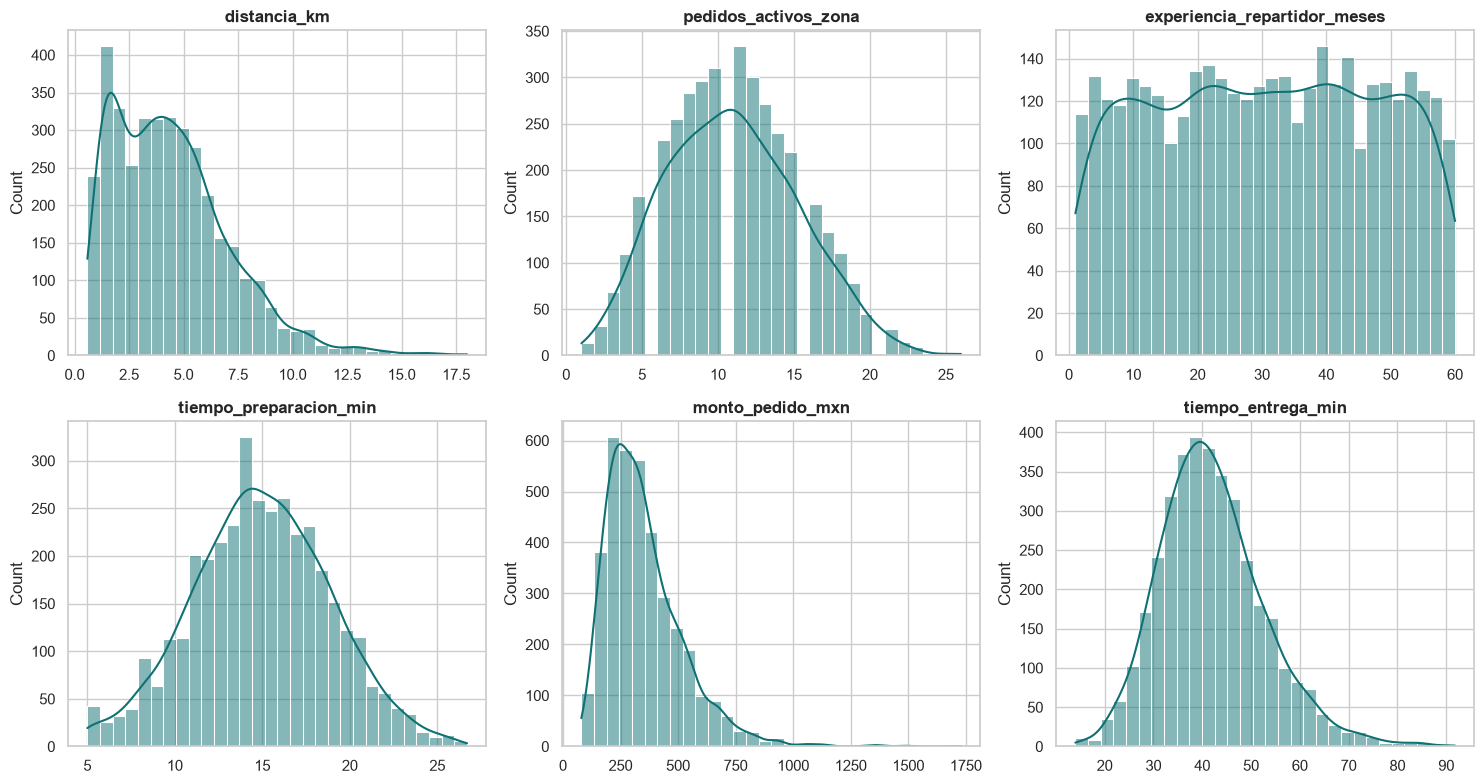

,count,mean,std,min,25%,50%,75%,max
distancia_km,3726.0,4.43,2.67,0.59,2.24,4.07,5.9,18.0
pedidos_activos_zona,3726.0,10.95,4.37,1.00,8.00,11.00,14.0,26.0
experiencia_repartidor_meses,3726.0,30.51,17.14,1.00,16.00,31.00,45.0,60.0
tiempo_preparacion_min,3726.0,14.94,3.94,5.00,12.30,14.90,17.6,26.7
monto_pedido_mxn,3726.0,351.48,169.22,80.00,232.00,319.00,433.0,1729.0
tiempo_entrega_min,3726.0,42.04,10.78,14.00,34.70,41.00,48.2,91.8


In [11]:
cont = ["distancia_km", "pedidos_activos_zona", "experiencia_repartidor_meses",
        "tiempo_preparacion_min", "monto_pedido_mxn", "tiempo_entrega_min"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cont):
    sns.histplot(df[col], bins=30, kde=True, color=TEAL, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout(); plt.show()
df[cont].describe().T.round(2)

**Interpretación.** Ya limpio, el tiempo de entrega va de 14 a 92 min con media de 42 min y una cola a la derecha moderada. La distancia está sesgada a la derecha (mediana 4.1 km, pero hay pedidos de hasta 18 km). La experiencia de los repartidores está repartida de forma casi uniforme entre 1 y 60 meses, y la preparación es aproximadamente simétrica alrededor de 15 min. El monto del pedido (mediana \$319 MXN) tiene cola larga.

### $\color{#dda}{\text{¿Cómo se relacionan las variables entre sí?}}$

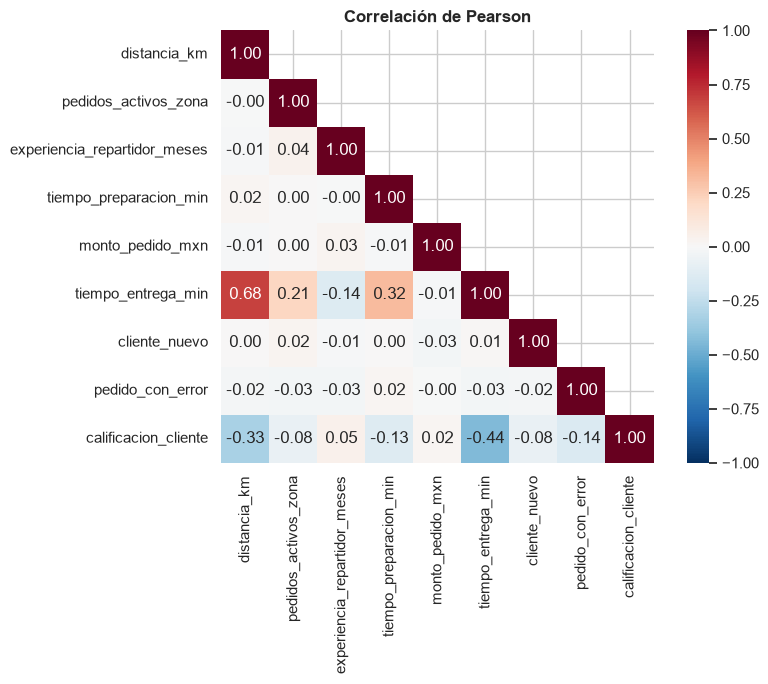

In [12]:
corr = df[cont + ["cliente_nuevo", "pedido_con_error", "calificacion_cliente"]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlación de Pearson")
plt.tight_layout(); plt.show()

**Interpretación.**

- La **distancia** es lo que más se mueve con el tiempo de entrega (r = 0.68), seguida del **tiempo de preparación** (0.32), los **pedidos activos en la zona** (0.21) y, en sentido contrario, la **experiencia del repartidor** (−0.14). El monto del pedido y si el cliente es nuevo no tienen relación con el tiempo.
- Los predictores casi no se correlacionan entre sí (todas |r| < 0.05): no hay señales de multicolinealidad entre variables continuas.
- La **calificación** baja cuando sube el tiempo de entrega (r = −0.44) y la distancia (−0.33), y cuando hay error en el pedido (−0.14).

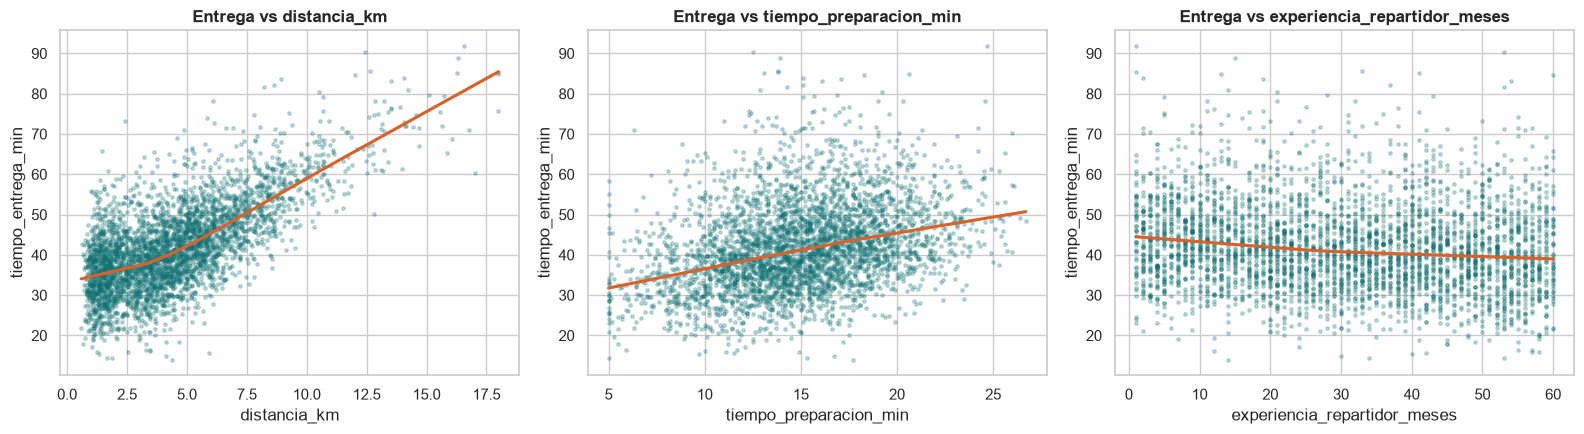

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["distancia_km", "tiempo_preparacion_min", "experiencia_repartidor_meses"]):
    sns.regplot(data=df, x=col, y="tiempo_entrega_min", ax=ax, scatter_kws=dict(s=6, alpha=0.25, color=TEAL),
                line_kws=dict(color=CORAL), lowess=True)
    ax.set_title(f"Entrega vs {col}")
plt.tight_layout(); plt.show()

**Interpretación.** La relación entre distancia y tiempo es claramente lineal (la curva suavizada es casi una recta), igual que con la preparación. La experiencia muestra una pendiente negativa suave: los repartidores con más meses entregan un poco más rápido. Esto justifica un modelo lineal sin transformaciones.

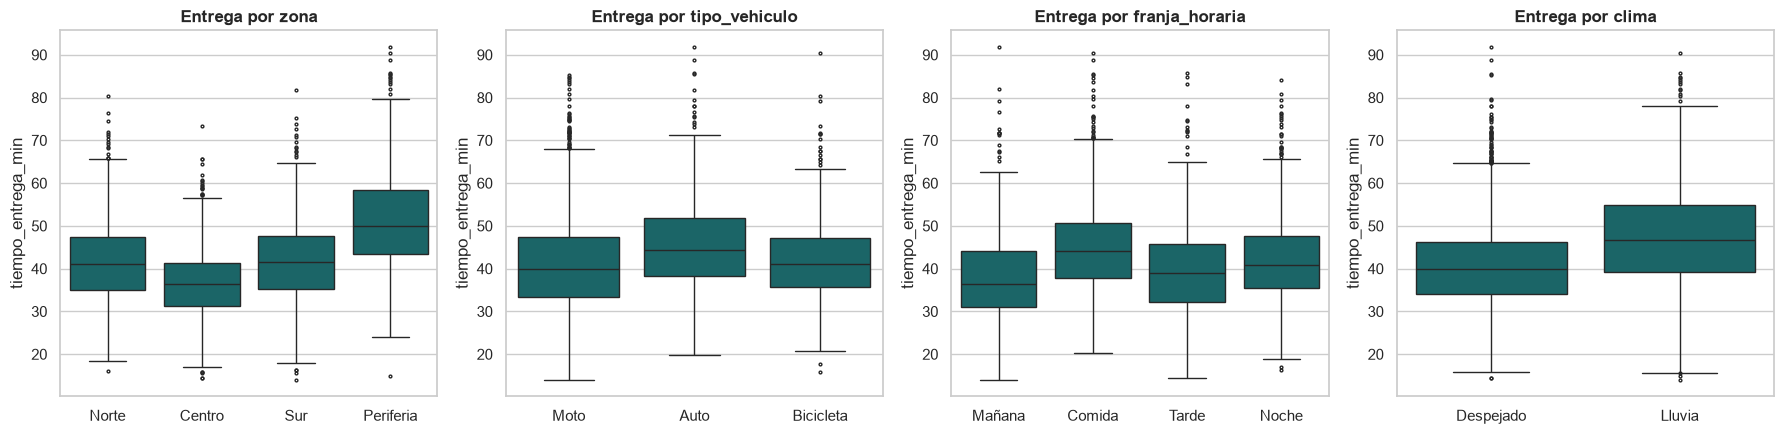

           count  mean  median
zona                          
Norte        934  41.6    41.0
Centro      1098  36.7    36.5
Sur          964  41.6    41.6
Periferia    730  51.1    50.0 

               count  mean  median
tipo_vehiculo                     
Moto            2397  41.0    39.8
Auto             694  45.6    44.3
Bicicleta        635  42.0    41.2 

                count  mean  median
franja_horaria                     
Mañana            533  38.0    36.4
Comida           1292  45.0    44.1
Tarde             740  39.8    38.9
Noche            1161  42.1    40.9 

           count  mean  median
clima                         
Despejado   2953  40.7    39.8
Lluvia       773  47.2    46.7 



In [14]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
ordenes = {"zona": ZONAS, "tipo_vehiculo": ["Moto", "Auto", "Bicicleta"],
           "franja_horaria": ["Mañana", "Comida", "Tarde", "Noche"], "clima": ["Despejado", "Lluvia"]}
for ax, (col, orden) in zip(axes, ordenes.items()):
    sns.boxplot(data=df, x=col, y="tiempo_entrega_min", order=orden, color=TEAL, fliersize=2, ax=ax)
    ax.set_title(f"Entrega por {col}"); ax.set_xlabel("")
plt.tight_layout(); plt.show()
for col in ordenes:
    print(df.groupby(col)["tiempo_entrega_min"].agg(["count", "mean", "median"]).round(1).loc[ordenes[col]], "\n")

**Interpretación (diferencias crudas, sin controlar por otros factores).** Con lluvia se tarda 6.5 min más (47.2 vs 40.7). La hora de la comida es la franja más lenta (45.0 min) y la mañana la más rápida (38.0). Los autos tardan más que las motos (45.6 vs 41.0). Entre zonas, Periferia es la más lenta (51.1) y Centro la más rápida (36.7), justo lo que dice el reporte de la Directora. Pero estas son comparaciones crudas: hay que ver qué tipo de pedidos tiene cada zona.

### $\color{#dda}{\text{¿Las zonas reciben el mismo tipo de pedidos?}}$

In [15]:
perfil_zona = df.groupby("zona").agg(
    pedidos=("id_pedido", "count"),
    entrega_media_min=("tiempo_entrega_min", "mean"),
    distancia_media_km=("distancia_km", "mean"),
    pedidos_activos=("pedidos_activos_zona", "mean"),
    preparacion_min=("tiempo_preparacion_min", "mean"),
    experiencia_meses=("experiencia_repartidor_meses", "mean"),
    pct_bicicleta=("tipo_vehiculo", lambda s: (s == "Bicicleta").mean() * 100),
    pct_lluvia=("clima", lambda s: (s == "Lluvia").mean() * 100),
    pct_mala_exp=("mala_experiencia", lambda s: s.mean() * 100),
).loc[ZONAS].round(1)
perfil_zona

,pedidos,entrega_media_min,distancia_media_km,pedidos_activos,preparacion_min,experiencia_meses,pct_bicicleta,pct_lluvia,pct_mala_exp
zona,,,,,,,,,
Norte,934,41.6,4.8,10.8,14.9,30.5,6.6,21.0,21.3
Centro,1098,36.7,1.7,11.0,14.9,30.6,40.1,19.9,16.0
Sur,964,41.6,4.9,11.0,14.9,30.6,8.5,20.4,24.1
Periferia,730,51.1,7.5,11.1,15.1,30.3,7.0,22.2,46.4


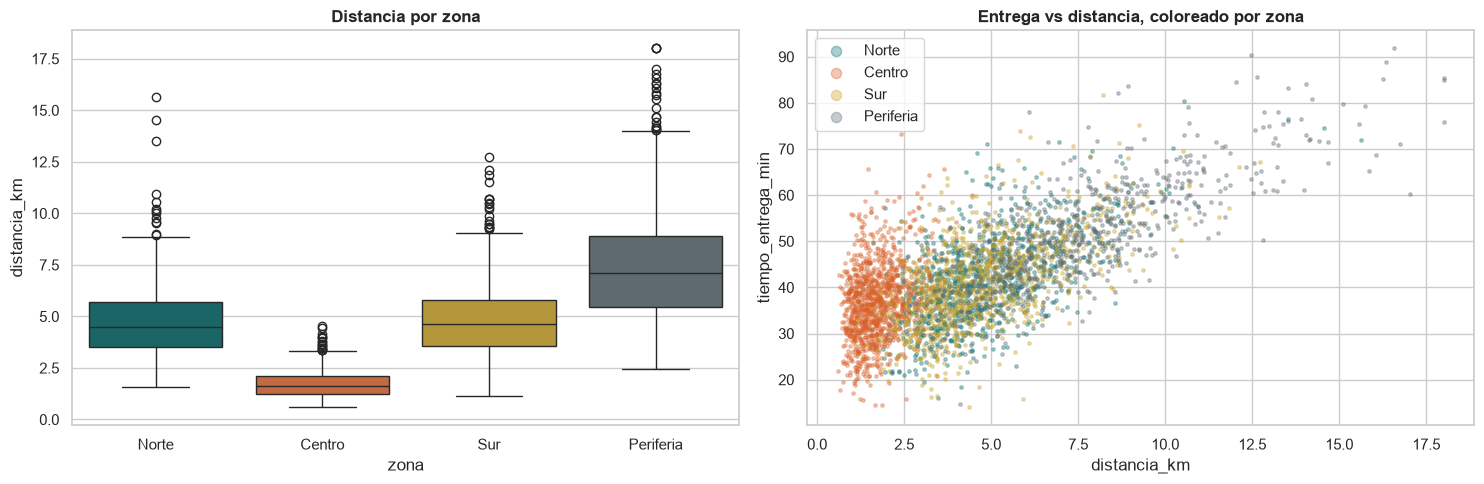

zona
Norte         8.8
Centro       21.9
Sur           8.8
Periferia     6.9
Name: min_por_km, dtype: float64

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x="zona", y="distancia_km", order=ZONAS, palette=ZONA_COLORES, hue="zona", legend=False, ax=axes[0])
axes[0].set_title("Distancia por zona")
for z in ZONAS:
    s = df[df["zona"] == z]
    axes[1].scatter(s["distancia_km"], s["tiempo_entrega_min"], s=6, alpha=0.35, color=ZONA_COLORES[z], label=z)
axes[1].set_xlabel("distancia_km"); axes[1].set_ylabel("tiempo_entrega_min")
axes[1].set_title("Entrega vs distancia, coloreado por zona"); axes[1].legend(markerscale=3)
plt.tight_layout(); plt.show()

# Minutos por km recorrido: una comparación cruda que ya descuenta la distancia
df.assign(min_por_km=df["tiempo_entrega_min"] / df["distancia_km"]).groupby("zona")["min_por_km"].median().loc[ZONAS].round(1)

**Interpretación.** Las zonas **no son comparables tal como están**:

- Un pedido de Periferia recorre en promedio **7.5 km**; uno de Centro, **1.7 km** (4.4 veces menos). Norte y Sur están en medio (~4.8 km).
- **40 % de los pedidos de Centro van en bicicleta**, contra 7–9 % en las demás zonas.
- En lo demás (carga de pedidos activos, preparación, experiencia, lluvia, franja) las zonas son prácticamente iguales.

En la gráfica de dispersión los pedidos de Centro se concentran a la izquierda (distancias cortas) y los de Periferia a la derecha, pero **todos siguen la misma recta**. Los minutos por km dicen lo mismo: Centro tarda una mediana de 21.9 min por km recorrido contra 6.9 de Periferia. (Este cociente exagera en pedidos cortos porque la preparación es un tiempo fijo, pero la dirección es clara.) La hipótesis para la Parte 3 es que Periferia parece lenta porque sus pedidos están lejos, no por ser Periferia.

### $\color{#dda}{\text{¿Qué acompaña a una mala experiencia?}}$

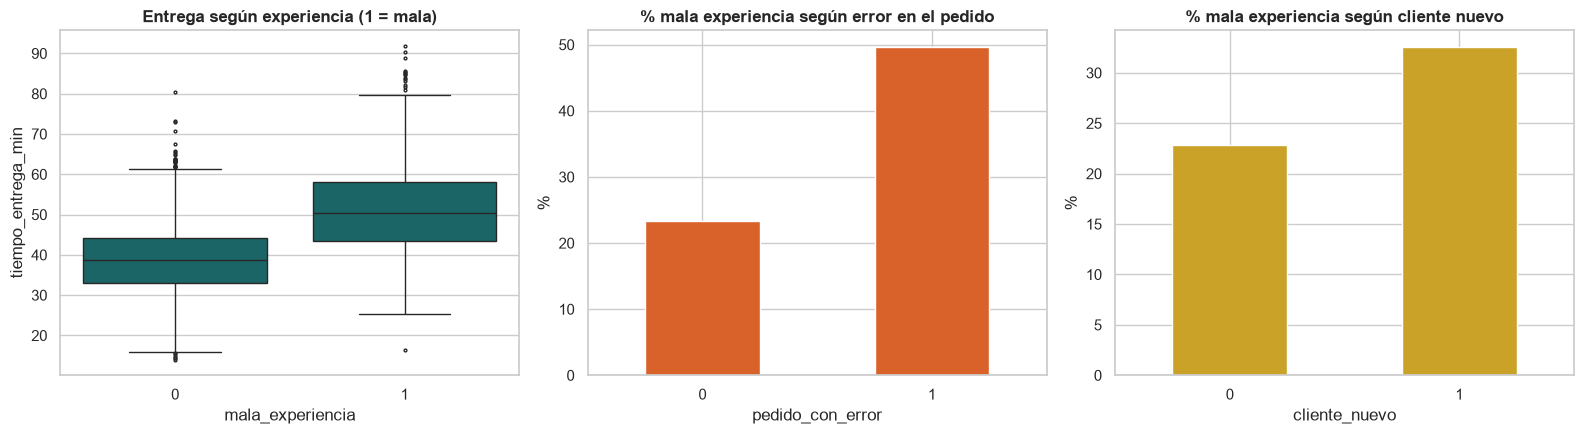

calificacion_cliente
1     436
2     510
3     542
4    1136
5    1102


,pedido_con_error,cliente_nuevo
0,23.3,22.9
1,49.7,32.6


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df, x="mala_experiencia", y="tiempo_entrega_min", color=TEAL, fliersize=2, ax=axes[0])
axes[0].set_title("Entrega según experiencia (1 = mala)")
(df.groupby("pedido_con_error")["mala_experiencia"].mean() * 100).plot.bar(color=CORAL, ax=axes[1])
axes[1].set_title("% mala experiencia según error en el pedido"); axes[1].set_ylabel("%")
(df.groupby("cliente_nuevo")["mala_experiencia"].mean() * 100).plot.bar(color=GOLD, ax=axes[2])
axes[2].set_title("% mala experiencia según cliente nuevo"); axes[2].set_ylabel("%")
for ax in axes[1:]: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

print(df["calificacion_cliente"].value_counts().sort_index().to_string())
tabla = pd.DataFrame({c: df.groupby(c)["mala_experiencia"].mean().mul(100).round(1)
                      for c in ["pedido_con_error", "cliente_nuevo"]})
tabla

In [18]:
bins = pd.cut(df["tiempo_entrega_min"], [0, 30, 40, 50, 60, 80, 200])
(df.groupby(bins, observed=True)["mala_experiencia"].agg(["count", "mean"])
   .assign(mean=lambda x: (x["mean"] * 100).round(1)).rename(columns={"mean": "% mala exp"}))

,count,% mala exp
tiempo_entrega_min,,
"(0, 30]",433,2.8
"(30, 40]",1295,10.0
"(40, 50]",1235,26.0
"(50, 60]",537,54.6
"(60, 80]",211,83.9
"(80, 200]",15,93.3


**Interpretación.** La mala experiencia sube con fuerza con el tiempo de entrega: **2.8 %** en entregas de 30 min o menos, **26 %** entre 40 y 50 min, **55 %** entre 50 y 60 min y **84 %** entre 60 y 80 min. Cuando el cliente reporta un error en el pedido, la tasa de mala experiencia se duplica (49.7 % vs 23.3 %), y los clientes nuevos califican mal más seguido (32.6 % vs 22.9 %). Por zona, Periferia tiene la tasa más alta (46.4 %) y Centro la más baja (16.0 %), lo cual probablemente también se explica por la distancia.

Ojo: el tiempo de entrega y el error **se conocen después** de la entrega. Para mandar el cupón al momento del pedido habrá que usar lo que predice el tiempo (distancia, clima, vehículo…), no el tiempo mismo.

### $\color{#dda}{\text{Hallazgos para verificar más adelante}}$

| Líder | Hallazgo exploratorio | Dónde se verifica |
|---|---|---|
| **Operaciones** | La distancia es el factor dominante (r = 0.68); la lluvia (+6.5 min crudos), la hora de comida y la preparación también pesan. | Parte 2: regresión múltiple, cuántos minutos aporta cada factor manteniendo los demás fijos. |
| **Directora Regional** | Periferia es la más lenta en crudo (51.1 vs 36.7 min), pero sus pedidos recorren 4.4 veces más distancia que los de Centro. Sospecha: la diferencia es distancia, no zona. | Parte 3: ANOVA + Tukey vs. coeficientes de zona en la regresión de la Parte 2. |
| **Experiencia del Cliente** | La mala experiencia se dispara arriba de 50 min de entrega y con errores en el pedido; los clientes nuevos son más exigentes. | Parte 4: regresión logística, separando causas (después de la entrega) de señales disponibles al hacer el pedido. |

---
# $\color{#dda}{\text{Parte 2. Operaciones: ¿qué hace lenta una entrega?}}$

## $\color{#dda}{\text{2.1 Selección de predictores}}$

Modelo lineal normal: $y = X\beta + e$, con $e_i \sim N(0, \sigma^2)$ independientes. Cada $\beta_j$ es el cambio esperado en minutos de entrega por cada unidad adicional de $x_j$, manteniendo constantes las demás variables (*ceteris paribus*). Las categóricas entran con $k-1$ variables dummy; la categoría de referencia queda absorbida en $\beta_0$.

Partimos de **todas las variables que existen antes de la entrega**: distancia, pedidos activos en la zona, experiencia del repartidor, preparación, monto, cliente nuevo, zona, vehículo, franja y clima. Se excluyen `pedido_con_error` y `calificacion_cliente` porque ocurren *después* de entregar (bitácora #7). La zona se incluye obligatoriamente porque se usa en la Parte 3.

In [19]:
Z = "C(zona, Treatment('Norte'))"
V = "C(tipo_vehiculo, Treatment('Moto'))"
F = "C(franja_horaria, Treatment('Mañana'))"
CL = "C(clima, Treatment('Despejado'))"

f_completo = (f"tiempo_entrega_min ~ distancia_km + pedidos_activos_zona + experiencia_repartidor_meses "
              f"+ tiempo_preparacion_min + monto_pedido_mxn + cliente_nuevo + {Z} + {V} + {F} + {CL}")
m_completo = smf.ols(f_completo, data=train).fit()
print(m_completo.summary())

                            OLS Regression Results                            
Dep. Variable:     tiempo_entrega_min   R-squared:                       0.745
Model:                            OLS   Adj. R-squared:                  0.743
Method:                 Least Squares   F-statistic:                     504.0
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:05:38   Log-Likelihood:                -8130.2
No. Observations:                2608   AIC:                         1.629e+04
Df Residuals:                    2592   BIC:                         1.639e+04
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------

`monto_pedido_mxn` (p = 0.72) y `cliente_nuevo` (p = 0.81) no son significativos. Probamos si se pueden quitar juntos con una **F parcial**, y de paso si la distancia cuesta distinto según el vehículo (interacción).

- **F parcial 1. H₀:** los coeficientes de monto y cliente nuevo son ambos cero (no aportan nada al explicar el tiempo de entrega una vez que están los demás factores). **H₁:** al menos uno es distinto de cero.
- **F parcial 2. H₀:** el efecto de cada km extra es el mismo en moto, auto y bicicleta. **H₁:** al menos un vehículo tiene un costo por km distinto.

In [20]:
f_final = (f"tiempo_entrega_min ~ distancia_km + pedidos_activos_zona + experiencia_repartidor_meses "
           f"+ tiempo_preparacion_min + {Z} + {V} + {F} + {CL}")
m_ols = smf.ols(f_final, data=train).fit()

# F parcial: ¿monto_pedido_mxn y cliente_nuevo aportan algo una vez que están los demás?
print("F parcial (modelo final vs. modelo con monto y cliente_nuevo):")
print(anova_lm(m_ols, m_completo).round(4))

# F parcial: ¿la distancia cuesta distinto según el vehículo (interacción)?
m_inter = smf.ols(f_final + f" + distancia_km:{V}", data=train).fit()
print("\nF parcial (interacción distancia x vehículo):")
print(anova_lm(m_ols, m_inter).round(4))

F parcial (modelo final vs. modelo con monto y cliente_nuevo):
   df_resid         ssr  df_diff  ss_diff       F  Pr(>F)
0    2594.0  77910.8395      0.0      NaN     NaN     NaN
1    2592.0  77905.0271      2.0   5.8124  0.0967  0.9078

F parcial (interacción distancia x vehículo):
   df_resid         ssr  df_diff  ss_diff       F  Pr(>F)
0    2594.0  77910.8395      0.0      NaN     NaN     NaN
1    2592.0  77822.1618      2.0  88.6778  1.4768  0.2286


**Interpretación.**

- **Monto y cliente nuevo:** F = 0.10, p = 0.91 > 0.05. No rechazamos H₀: el monto del pedido y si el cliente es nuevo no cambian el tiempo de entrega. Se quitan; el modelo queda más simple sin perder nada (R² ajustada igual: 0.743).
- **Interacción distancia × vehículo:** F = 1.48, p = 0.23 > 0.05. No rechazamos H₀: cada km cuesta lo mismo sin importar el vehículo. El vehículo agrega un tiempo fijo, no una velocidad distinta por km. Se usa el modelo sin interacción.

## $\color{#dda}{\text{2.2 Modelo final}}$

In [21]:
print(m_ols.summary())

                            OLS Regression Results                            
Dep. Variable:     tiempo_entrega_min   R-squared:                       0.745
Model:                            OLS   Adj. R-squared:                  0.743
Method:                 Least Squares   F-statistic:                     581.9
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:05:38   Log-Likelihood:                -8130.3
No. Observations:                2608   AIC:                         1.629e+04
Df Residuals:                    2594   BIC:                         1.637e+04
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------

## $\color{#dda}{\text{2.3 Prueba F global}}$

- **H₀:** β₁ = β₂ = … = β₁₃ = 0. Ninguno de los factores ayuda a explicar el tiempo de entrega; el modelo no es mejor que prometerle a todos el tiempo promedio (42 min).
- **H₁:** al menos un βⱼ ≠ 0. Al menos un factor explica parte de la variación en el tiempo de entrega.

In [22]:
f_crit = stats.f.ppf(1 - ALPHA, m_ols.df_model, m_ols.df_resid)
print(f"F({int(m_ols.df_model)}, {int(m_ols.df_resid)}) = {m_ols.fvalue:.2f}   F crítica = {f_crit:.3f}   p = {m_ols.f_pvalue:.2e}")
print("Decisión:", "rechazar H0" if m_ols.f_pvalue < ALPHA else "no rechazar H0")
print(f"R² = {m_ols.rsquared:.3f}   R² ajustada = {m_ols.rsquared_adj:.3f}")

F(13, 2594) = 581.89   F crítica = 1.724   p = 0.00e+00
Decisión: rechazar H0
R² = 0.745   R² ajustada = 0.743


**Interpretación.** F(13, 2594) = 581.9, muy por arriba de la F crítica de 1.72, con p ≈ 0 < 0.05. **Rechazamos H₀**: el modelo en conjunto sí explica el tiempo de entrega. El R² de 0.745 dice que los factores del modelo explican **75 % de la variación** en los tiempos de entrega; el 25 % restante es variación que no medimos (tráfico puntual, semáforos, encontrar el domicilio, etc.).

## $\color{#dda}{\text{2.4 Pruebas t individuales}}$

Para cada coeficiente βⱼ:
- **H₀:** βⱼ = 0. Manteniendo fijos los demás factores, este factor no cambia el tiempo de entrega.
- **H₁:** βⱼ ≠ 0. Este factor sí cambia el tiempo de entrega.

In [23]:
coefs = pd.DataFrame({"coef_min": m_ols.params, "t": m_ols.tvalues, "p": m_ols.pvalues,
                      "IC95_inf": m_ols.conf_int()[0], "IC95_sup": m_ols.conf_int()[1]})
coefs["decisión"] = np.where(coefs["p"] < ALPHA, "rechazar H0", "no rechazar H0")
coefs.round(4)

,coef_min,t,p,IC95_inf,IC95_sup,decisión
Intercept,8.3274,12.5028,0.0000,7.0214,9.6335,rechazar H0
"C(zona, Treatment('Norte'))[T.Centro]",3.8890,10.6253,0.0000,3.1713,4.6067,rechazar H0
"C(zona, Treatment('Norte'))[T.Periferia]",0.6048,1.6779,0.0935,-0.1020,1.3117,no rechazar H0
"C(zona, Treatment('Norte'))[T.Sur]",-0.0608,-0.2029,0.8392,-0.6489,0.5272,no rechazar H0
"C(tipo_vehiculo, Treatment('Moto'))[T.Auto]",3.0100,10.6364,0.0000,2.4551,3.5650,rechazar H0
"C(tipo_vehiculo, Treatment('Moto'))[T.Bicicleta]",5.2604,16.3014,0.0000,4.6276,5.8932,rechazar H0
"C(franja_horaria, Treatment('Mañana'))[T.Comida]",4.0836,9.6476,0.0000,3.2536,4.9136,rechazar H0
"C(franja_horaria, Treatment('Mañana'))[T.Noche]",2.4138,6.0888,0.0000,1.6364,3.1911,rechazar H0
"C(franja_horaria, Treatment('Mañana'))[T.Tarde]",0.8950,2.3775,0.0175,0.1569,1.6332,rechazar H0
"C(clima, Treatment('Despejado'))[T.Lluvia]",5.8184,21.7566,0.0000,5.2940,6.3428,rechazar H0


In [24]:
# Prueba conjunta por variable (cada categórica se prueba completa, no nivel por nivel)
anova_lm(m_ols, typ=2).round(4)

,sum_sq,df,F,PR(>F)
"C(zona, Treatment('Norte'))",4421.9547,3.0,49.0755,0.0
"C(tipo_vehiculo, Treatment('Moto'))",9993.7011,2.0,166.3675,0.0
"C(franja_horaria, Treatment('Mañana'))",3403.0984,3.0,37.7681,0.0
"C(clima, Treatment('Despejado'))",14217.1238,1.0,473.3516,0.0
distancia_km,82246.0404,1.0,2738.3382,0.0
pedidos_activos_zona,2769.3539,1.0,92.2042,0.0
experiencia_repartidor_meses,5795.1804,1.0,192.9475,0.0
tiempo_preparacion_min,26909.8301,1.0,895.9485,0.0
Residual,77910.8395,2594.0,NaN,NaN


**Interpretación (cada efecto se lee "manteniendo todo lo demás constante").**

| Factor | Efecto | IC 95 % | Decisión | Lectura de negocio |
|---|---|---|---|---|
| Distancia | **+3.25 min por km** | 3.12 a 3.37 | Rechazar H₀ | Un pedido a 5 km tarda unos 13 min más que uno a 1 km. Es, por mucho, el factor más importante. |
| Preparación | **+0.82 min por min de preparación** | 0.77 a 0.87 | Rechazar H₀ | Si el restaurante tarda 10 min más en preparar, la entrega se alarga 8.2 min. No es 1 a 1 porque parte de la preparación se traslapa con el traslado del repartidor al restaurante. |
| Lluvia (vs Despejado) | **+5.8 min** | 5.3 a 6.3 | Rechazar H₀ | La lluvia agrega casi 6 min a cualquier pedido. |
| Bicicleta (vs Moto) | **+5.3 min** | 4.6 a 5.9 | Rechazar H₀ | Mismo pedido, en bici tarda 5 min más que en moto. |
| Auto (vs Moto) | **+3.0 min** | 2.5 a 3.6 | Rechazar H₀ | El auto es 3 min más lento que la moto (tráfico, estacionarse). |
| Comida (vs Mañana) | **+4.1 min** | 3.3 a 4.9 | Rechazar H₀ | La hora de comida es la franja más lenta. |
| Noche (vs Mañana) | **+2.4 min** | 1.6 a 3.2 | Rechazar H₀ | |
| Tarde (vs Mañana) | **+0.9 min** | 0.2 a 1.6 | Rechazar H₀ (p = 0.018) | Diferencia pequeña. |
| Pedidos activos en la zona | **+0.32 min por pedido activo** | 0.25 a 0.38 | Rechazar H₀ | Si hay 10 pedidos activos más en la zona, cada entrega tarda 3.2 min más: la saturación cuesta. |
| Experiencia del repartidor | **−0.087 min por mes** | −0.099 a −0.075 | Rechazar H₀ | Un repartidor con 1 año más de experiencia entrega 1.0 min más rápido; uno de 5 años vs uno nuevo, 5.1 min más rápido. |
| Centro (vs Norte) | **+3.9 min** | 3.2 a 4.6 | Rechazar H₀ | **A igual distancia, vehículo y clima, Centro es la zona más lenta.** Se analiza en la Parte 3. |
| Periferia (vs Norte) | +0.6 min | −0.1 a 1.3 | No rechazar H₀ (p = 0.09) | A igualdad de condiciones, Periferia no es más lenta que Norte. |
| Sur (vs Norte) | −0.1 min | −0.6 a 0.5 | No rechazar H₀ (p = 0.84) | Sur y Norte son equivalentes. |

El intercepto (8.3 min) no tiene lectura de negocio por sí solo: sería un pedido a 0 km, con 0 min de preparación y 0 pedidos activos, que no existe.

La tabla de prueba conjunta (ANOVA tipo II) confirma que **cada variable completa** es significativa (todas p ≈ 0), incluida la zona como un todo (F = 49.1), aunque solo Centro se distingue de Norte.

## $\color{#dda}{\text{2.5 Supuestos del modelo}}$

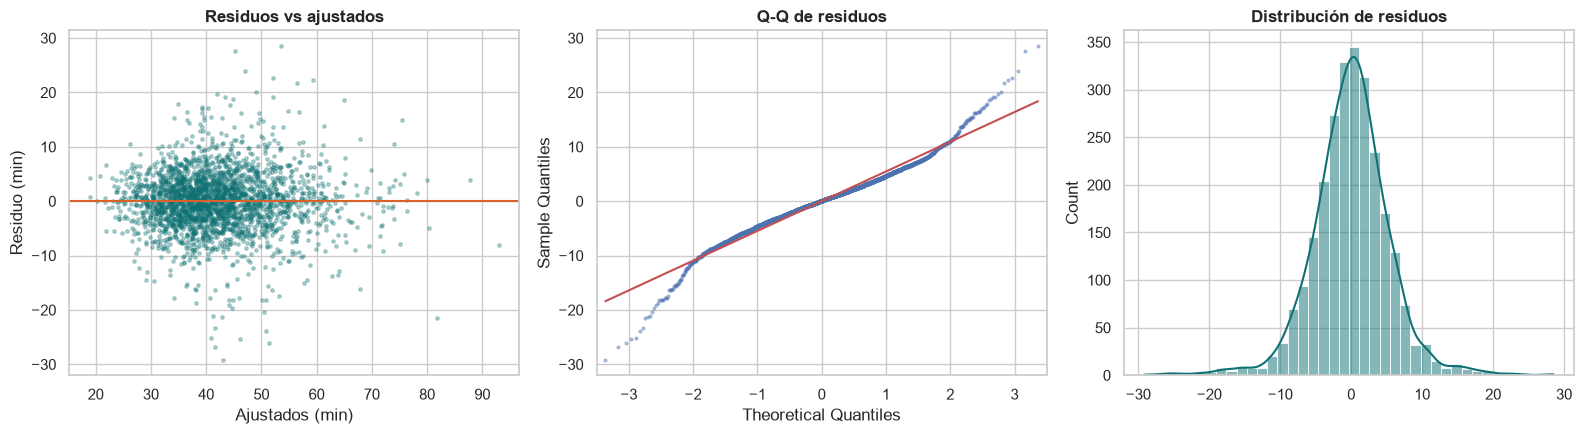

In [25]:
resid = m_ols.resid
fitted = m_ols.fittedvalues
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(fitted, resid, s=6, alpha=0.3, color=TEAL); axes[0].axhline(0, color=CORAL)
axes[0].set_xlabel("Ajustados (min)"); axes[0].set_ylabel("Residuo (min)"); axes[0].set_title("Residuos vs ajustados")
sm.qqplot(resid, line="s", ax=axes[1], markersize=2, alpha=0.4); axes[1].set_title("Q-Q de residuos")
sns.histplot(resid, bins=40, kde=True, color=TEAL, ax=axes[2]); axes[2].set_title("Distribución de residuos")
plt.tight_layout(); plt.show()

Cuatro pruebas formales:

| Supuesto | Prueba | H₀ | H₁ |
|---|---|---|---|
| Linealidad | RESET de Ramsey | La relación es lineal; agregar términos cuadráticos de los valores ajustados no mejora el modelo. | Falta una forma no lineal. |
| Normalidad de errores | Shapiro-Wilk y Jarque-Bera | Los residuos son normales. | No son normales. |
| Varianza constante | Breusch-Pagan | La varianza del error es la misma para todos los pedidos. | La varianza depende de algún predictor. |
| Independencia | Durbin-Watson | No hay autocorrelación (DW ≈ 2). | Errores consecutivos están correlacionados. |

In [26]:
reset = linear_reset(m_ols, power=2, use_f=True)
sw_stat, sw_p = stats.shapiro(resid)
jb_stat, jb_p, skew, kurt = jarque_bera(resid)
bp_lm, bp_p, _, _ = het_breuschpagan(resid, m_ols.model.exog)
dw = durbin_watson(resid)
print(f"Linealidad   – RESET:         F = {reset.fvalue:.3f}, p = {reset.pvalue:.4f}")
print(f"Normalidad   – Shapiro-Wilk:  W = {sw_stat:.4f}, p = {sw_p:.2e}")
print(f"Normalidad   – Jarque-Bera:   JB = {jb_stat:.2f}, p = {jb_p:.2e}  (sesgo = {skew:.2f}, curtosis = {kurt:.2f})")
print(f"Homocedast.  – Breusch-Pagan: LM = {bp_lm:.2f}, p = {bp_p:.2e}")
print(f"Independencia– Durbin-Watson: {dw:.3f}")

Linealidad   – RESET:         F = 2.452, p = 0.1175
Normalidad   – Shapiro-Wilk:  W = 0.9657, p = 1.96e-24
Normalidad   – Jarque-Bera:   JB = 1006.93, p = 2.23e-219  (sesgo = -0.13, curtosis = 6.03)
Homocedast.  – Breusch-Pagan: LM = 481.53, p = 1.22e-94
Independencia– Durbin-Watson: 1.901


In [27]:
X = pd.DataFrame(m_ols.model.exog, columns=m_ols.model.exog_names)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns, name="VIF")
vif.drop("Intercept").round(2).sort_values(ascending=False)

C(franja_horaria, Treatment('Mañana'))[T.Comida]    3.52
C(franja_horaria, Treatment('Mañana'))[T.Noche]     2.92
C(zona, Treatment('Norte'))[T.Centro]               2.36
distancia_km                                        2.33
C(franja_horaria, Treatment('Mañana'))[T.Tarde]     1.97
C(zona, Treatment('Norte'))[T.Periferia]            1.82
pedidos_activos_zona                                1.81
C(zona, Treatment('Norte'))[T.Sur]                  1.51
C(tipo_vehiculo, Treatment('Moto'))[T.Bicicleta]    1.21
C(tipo_vehiculo, Treatment('Moto'))[T.Auto]         1.06
C(clima, Treatment('Despejado'))[T.Lluvia]          1.00
experiencia_repartidor_meses                        1.00
tiempo_preparacion_min                              1.00
Name: VIF, dtype: float64

In [28]:
infl = m_ols.get_influence()
cooks = infl.cooks_distance[0]
umbral = 4 / len(train)
print(f"Pedidos con Cook > 4/n: {(cooks > umbral).sum()} de {len(train)}   Cook máximo: {cooks.max():.4f}")

# ¿Cambian las conclusiones si se quitan los pedidos influyentes?
m_sin_infl = smf.ols(f_final, data=train[cooks <= umbral]).fit()
pd.DataFrame({"con_todos": m_ols.params, "sin_influyentes": m_sin_infl.params}).round(2)

Pedidos con Cook > 4/n: 149 de 2608   Cook máximo: 0.0200


,con_todos,sin_influyentes
Intercept,8.33,8.69
"C(zona, Treatment('Norte'))[T.Centro]",3.89,4.03
"C(zona, Treatment('Norte'))[T.Periferia]",0.60,0.49
"C(zona, Treatment('Norte'))[T.Sur]",-0.06,-0.10
"C(tipo_vehiculo, Treatment('Moto'))[T.Auto]",3.01,3.03
"C(tipo_vehiculo, Treatment('Moto'))[T.Bicicleta]",5.26,5.08
"C(franja_horaria, Treatment('Mañana'))[T.Comida]",4.08,4.49
"C(franja_horaria, Treatment('Mañana'))[T.Noche]",2.41,2.64
"C(franja_horaria, Treatment('Mañana'))[T.Tarde]",0.90,1.22
"C(clima, Treatment('Despejado'))[T.Lluvia]",5.82,5.79


**Interpretación.**

- **Linealidad (RESET F = 2.45, p = 0.12 > 0.05):** no rechazamos H₀. La forma lineal es adecuada; la gráfica de residuos vs ajustados no muestra curvatura. Los "minutos por km" del modelo son confiables en todo el rango.
- **Normalidad (Shapiro-Wilk W = 0.966, p ≈ 0; JB = 1,007, p ≈ 0):** ambas pruebas rechazan H₀. Los residuos son casi simétricos (sesgo −0.13) pero con **colas pesadas** (curtosis 6.0 vs 3 de la normal): hay más pedidos con sorpresas grandes de lo que la normal predice. *Qué afecta:* con 2,608 pedidos, el teorema del límite central hace que las pruebas t y F sobre los coeficientes sigan siendo válidas. Lo que sí afecta es el **intervalo de predicción** de un pedido individual; por eso en 2.7 se verifica su cobertura real en datos nuevos.
- **Varianza constante (BP LM = 481.5, p ≈ 0):** rechazamos H₀. Abajo se busca la causa.
- **Independencia (DW = 1.90):** muy cerca de 2, sin autocorrelación. Limitación: las filas no traen fecha y hora, así que no podemos revisar si los pedidos del mismo día o del mismo repartidor están correlacionados.
- **Multicolinealidad:** todos los VIF están por debajo de 3.6 (umbral de preocupación: 5 o 10). Los efectos de cada factor se pueden separar sin problema.
- **Observaciones influyentes:** la distancia de Cook máxima es 0.02, muy lejos de 1. Hay 149 pedidos por arriba de la regla 4/n, pero al quitarlos todos los coeficientes se mueven menos de 0.4 min: ningún pedido individual está determinando las conclusiones.

**¿Qué tipo de problema tenemos?** Siguiendo la distinción del material: la linealidad se cumple, así que **no hay comportamiento inconsistente del modelo** (no predice bien en un rango y mal en otro). Lo que falla es normalidad y homocedasticidad, que es un problema de **inferencia no confiable**: los coeficientes siguen bien, pero hay que verificar que los p-values y los intervalos sigan siendo válidos. Eso se hace abajo.

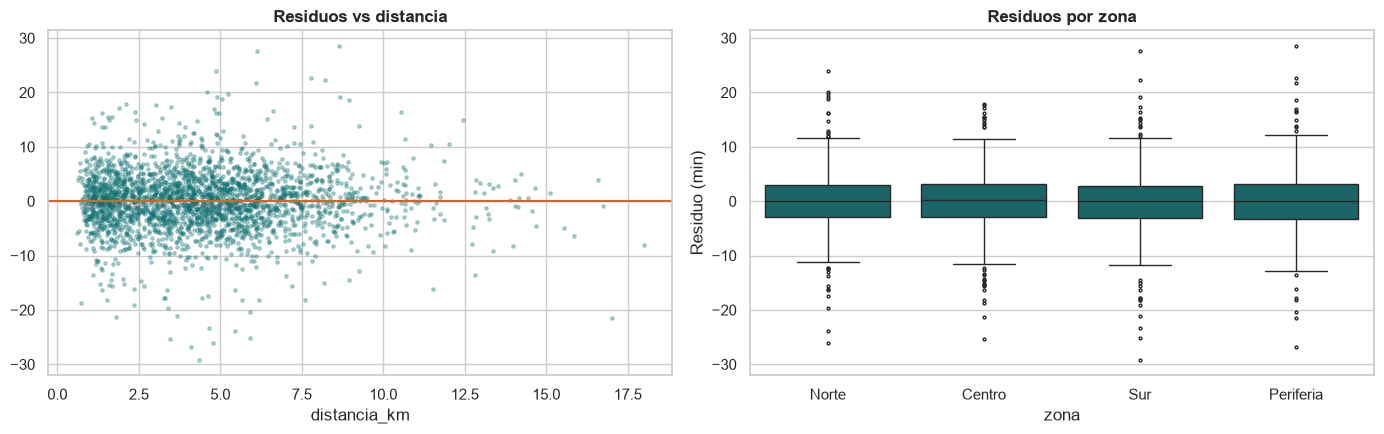

Desviación estándar de los residuos (min) por grupo:
  cuartil de distancia: (0.589, 2.278] = 5.18, (2.278, 4.11] = 5.46, (4.11, 5.912] = 5.67, (5.912, 18.0] = 5.55
  clima: Despejado = 3.96, Lluvia = 9.26
  vehículo: Auto = 5.17, Bicicleta = 4.96, Moto = 5.67
  franja: Comida = 5.20, Mañana = 5.84, Noche = 5.29, Tarde = 5.89
  zona: Centro = 5.30, Norte = 5.31, Periferia = 5.72, Sur = 5.60


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(train["distancia_km"], resid, s=6, alpha=0.3, color=TEAL); axes[0].axhline(0, color=CORAL)
axes[0].set_xlabel("distancia_km"); axes[0].set_title("Residuos vs distancia")
sns.boxplot(x=train["zona"], y=resid, order=ZONAS, color=TEAL, fliersize=2, ax=axes[1])
axes[1].set_title("Residuos por zona"); axes[1].set_ylabel("Residuo (min)")
plt.tight_layout(); plt.show()
print("Desviación estándar de los residuos (min) por grupo:")
for nombre, g in [("cuartil de distancia", pd.qcut(train["distancia_km"], 4)), ("clima", train["clima"]),
                  ("vehículo", train["tipo_vehiculo"]), ("franja", train["franja_horaria"]), ("zona", train["zona"])]:
    print(f"  {nombre}: " + ", ".join(f"{k} = {v:.2f}" for k, v in resid.groupby(g, observed=True).std().items()))

**¿De dónde viene la heterocedasticidad?** De la **lluvia**: con cielo despejado los residuos tienen una desviación de 4.0 min; con lluvia, **9.3 min**. Es decir, la lluvia no solo agrega 5.8 min en promedio, también hace el tiempo de entrega mucho **más impredecible**. Por distancia, vehículo, franja o zona la dispersión es prácticamente igual (5–6 min). Esta mezcla de dos niveles de ruido también explica las colas pesadas que vimos en la prueba de normalidad.

*Qué afecta:* los coeficientes siguen siendo insesgados, pero los errores estándar clásicos pueden estar mal. Se recalculan con errores robustos HC3:

In [30]:
# Errores estándar robustos a heterocedasticidad (HC3): mismos coeficientes, p-values corregidos
m_hc3 = smf.ols(f_final, data=train).fit(cov_type="HC3")
pd.DataFrame({"coef": m_ols.params, "p_clásico": m_ols.pvalues, "p_HC3": m_hc3.pvalues}).round(4)

,coef,p_clásico,p_HC3
Intercept,8.3274,0.0000,0.0000
"C(zona, Treatment('Norte'))[T.Centro]",3.8890,0.0000,0.0000
"C(zona, Treatment('Norte'))[T.Periferia]",0.6048,0.0935,0.0968
"C(zona, Treatment('Norte'))[T.Sur]",-0.0608,0.8392,0.8392
"C(tipo_vehiculo, Treatment('Moto'))[T.Auto]",3.0100,0.0000,0.0000
"C(tipo_vehiculo, Treatment('Moto'))[T.Bicicleta]",5.2604,0.0000,0.0000
"C(franja_horaria, Treatment('Mañana'))[T.Comida]",4.0836,0.0000,0.0000
"C(franja_horaria, Treatment('Mañana'))[T.Noche]",2.4138,0.0000,0.0000
"C(franja_horaria, Treatment('Mañana'))[T.Tarde]",0.8950,0.0175,0.0261
"C(clima, Treatment('Despejado'))[T.Lluvia]",5.8184,0.0000,0.0000


**Interpretación.** Con errores robustos **ninguna decisión cambia**: todo lo que era significativo lo sigue siendo (Tarde pasa de p = 0.018 a 0.026, aún < 0.05) y Periferia y Sur siguen sin ser distintas de Norte. Podemos confiar en las conclusiones de 2.4. La consecuencia práctica es para la promesa al cliente: el margen de error debe ser **más amplio cuando llueve** (sección 2.7).

## $\color{#dda}{\text{2.6 Desempeño en datos no vistos (conjunto de prueba)}}$

In [31]:
y_test = test["tiempo_entrega_min"]
pred_test = m_ols.predict(test)
pred_train = m_ols.fittedvalues

def metricas_reg(y, p):
    return pd.Series({"R²": r2_score(y, p), "MAE (min)": mean_absolute_error(y, p),
                      "MSE (min²)": mean_squared_error(y, p), "RMSE (min)": mean_squared_error(y, p) ** 0.5,
                      "MAPE": mean_absolute_percentage_error(y, p)})

pd.DataFrame({"entrenamiento": metricas_reg(train["tiempo_entrega_min"], pred_train),
              "prueba": metricas_reg(y_test, pred_test)}).round(3)

,entrenamiento,prueba
R²,0.745,0.753
MAE (min),3.983,4.011
MSE (min²),29.874,28.254
RMSE (min),5.466,5.315
MAPE,0.104,0.101


**Interpretación de cada métrica en el conjunto de prueba (1,118 pedidos que el modelo nunca vio):**

- **R² = 0.753:** el modelo explica el 75 % de la variación del tiempo de entrega en pedidos nuevos; el 25 % restante es ruido o factores que no medimos. Es igual que en entrenamiento (0.745), así que **no hay sobreajuste**: lo aprendido se generaliza. En entrenamiento la **R² ajustada** es 0.743, prácticamente igual a la R²: las variables del modelo se ganan su lugar y no hay predictores de relleno.
- **MAE = 4.0 min:** en promedio, la estimación se equivoca por 4 minutos (hacia arriba o hacia abajo).
- **MSE = 28.3 min²:** error cuadrático medio. Castiga más los errores grandes; está en minutos al cuadrado, por eso se interpreta mejor su raíz.
- **RMSE = 5.3 min:** el error típico de una estimación, con más peso a los errores grandes. Que sea mayor que el MAE (5.3 vs 4.0) confirma que hay algunos pedidos con errores grandes (los de lluvia).
- **MAPE = 10.1 %:** en promedio la estimación se aleja 10 % del tiempo real. Para un pedido de 40 min, eso es ±4 min.

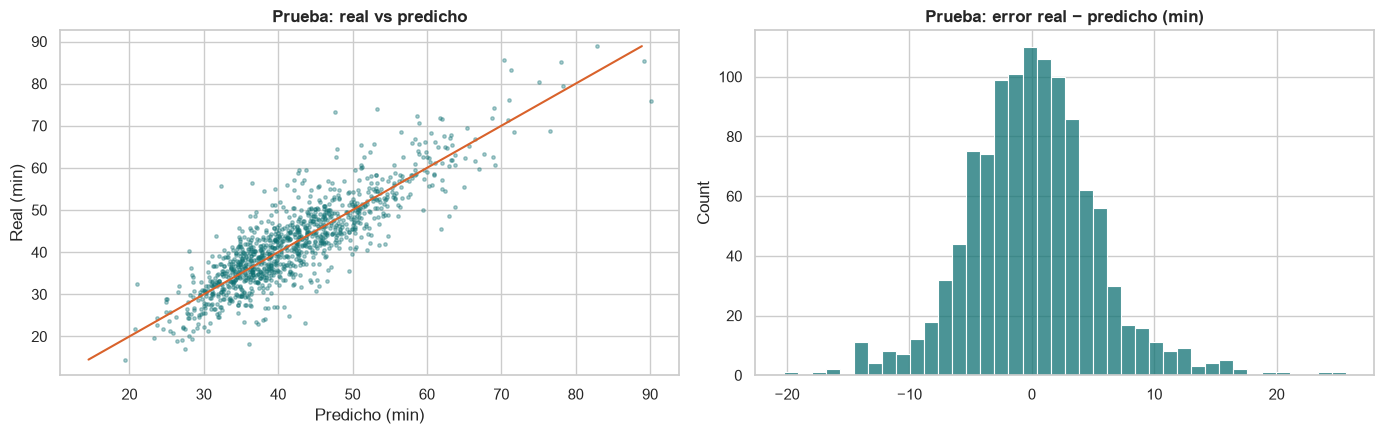

Pedidos de prueba con error dentro de ±5 min: 71.8%
Pedidos de prueba con error dentro de ±10 min: 93.2%
Pedidos que llegaron más de 10 min tarde vs. la predicción: 3.8%


In [32]:
err = y_test - pred_test
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(pred_test, y_test, s=6, alpha=0.35, color=TEAL)
lim = [y_test.min(), y_test.max()]; axes[0].plot(lim, lim, color=CORAL)
axes[0].set_xlabel("Predicho (min)"); axes[0].set_ylabel("Real (min)"); axes[0].set_title("Prueba: real vs predicho")
sns.histplot(err, bins=40, color=TEAL, ax=axes[1]); axes[1].set_title("Prueba: error real − predicho (min)")
plt.tight_layout(); plt.show()
for k in [5, 10]:
    print(f"Pedidos de prueba con error dentro de ±{k} min: {(err.abs() <= k).mean():.1%}")
print(f"Pedidos que llegaron más de 10 min tarde vs. la predicción: {(err > 10).mean():.1%}")

**Interpretación.** Los puntos siguen la diagonal sin curvas ni sesgos. **72 %** de los pedidos de prueba quedaron a menos de 5 min de su estimación y **93 %** a menos de 10 min. Solo 3.8 % llegó más de 10 min después de lo estimado.

## $\color{#dda}{\text{2.7 ¿Qué margen debe tener la estimación?}}$

In [33]:
# Intervalo de predicción al 95% para cada pedido de prueba: el "margen" de una promesa
pi = m_ols.get_prediction(test).summary_frame(alpha=0.05)
semi_ancho = (pi["obs_ci_upper"] - pi["obs_ci_lower"]) / 2
cobertura = ((y_test >= pi["obs_ci_lower"]) & (y_test <= pi["obs_ci_upper"])).mean()
print(f"Semiancho medio del intervalo de predicción 95%: ±{semi_ancho.mean():.1f} min")
print(f"Cobertura real en prueba: {cobertura:.1%} de los pedidos cayeron dentro de su intervalo")
q90 = np.quantile(err, 0.90)
print(f"Percentil 90 del error en prueba: {q90:.1f} min  -> prometer 'predicción + {q90:.0f} min' llega a tiempo ~90% de las veces")

ejemplo = test.iloc[[0]]
pe = m_ols.get_prediction(ejemplo).summary_frame(alpha=0.05)
print(f"\nEjemplo: pedido {ejemplo['id_pedido'].iat[0]} ({ejemplo['zona'].iat[0]}, {ejemplo['distancia_km'].iat[0]} km, "
      f"{ejemplo['tipo_vehiculo'].iat[0]}, {ejemplo['clima'].iat[0]}): estimado {pe['mean'].iat[0]:.0f} min, "
      f"rango 95% {pe['obs_ci_lower'].iat[0]:.0f}–{pe['obs_ci_upper'].iat[0]:.0f} min; real {ejemplo['tiempo_entrega_min'].iat[0]:.0f} min")

Semiancho medio del intervalo de predicción 95%: ±10.8 min
Cobertura real en prueba: 94.3% de los pedidos cayeron dentro de su intervalo
Percentil 90 del error en prueba: 6.1 min  -> prometer 'predicción + 6 min' llega a tiempo ~90% de las veces

Ejemplo: pedido RMX-01073 (Centro, 1.31 km, Moto, Lluvia): estimado 41 min, rango 95% 31–52 min; real 45 min


In [34]:
# El error no es igual con lluvia que sin ella: margen empírico por clima en el conjunto de prueba
margen = err.groupby(test["clima"]).agg(
    pedidos="count", MAE=lambda e: e.abs().mean(), RMSE=lambda e: (e ** 2).mean() ** 0.5,
    p90_retraso=lambda e: e.quantile(0.90), p95_abs=lambda e: e.abs().quantile(0.95))
print("Error en prueba por clima (min):")
print(margen.round(1))

Error en prueba por clima (min):
           pedidos  MAE  RMSE  p90_retraso  p95_abs
clima                                              
Despejado      874  3.3   4.1          5.2      7.9
Lluvia         244  6.7   8.4         11.7     15.7


**Interpretación.**

- El intervalo de predicción al 95 % mide en promedio **±10.8 min** y en el conjunto de prueba contuvo al **94.3 %** de los pedidos, prácticamente el 95 % prometido. Aunque los residuos no son normales, el intervalo funciona en la práctica. Ejemplo: un pedido en Centro de 1.3 km, en moto y con lluvia, se estimó en 41 min con un rango de 31 a 52 min; llegó en 45.
- Pero ese ±10.8 es un promedio de dos situaciones muy distintas:
  - **Cielo despejado:** error típico (MAE) de 3.3 min; 95 % de los pedidos quedan a menos de **±8 min**; sumar **5 min** a la estimación cubre al 90 % de los pedidos.
  - **Lluvia:** error típico de 6.7 min; 95 % quedan a menos de **±16 min**; hay que sumar **12 min** para cubrir al 90 %.

In [35]:
# Impacto en minutos de un cambio "típico" (1 desviación estándar en continuas; el coeficiente en categóricas)
sd = train[["distancia_km", "pedidos_activos_zona", "experiencia_repartidor_meses", "tiempo_preparacion_min"]].std()
impacto = pd.concat([
    (m_ols.params[sd.index] * sd).rename(lambda s: f"{s} (+1 DE = {sd[s]:.1f})"),
    m_ols.params.filter(like="C(").rename(lambda s: s.replace("C(", "").split(",")[0] + " = " + s.split("[T.")[1].rstrip("]")),
]).sort_values(key=abs, ascending=False)
impacto.round(2).to_frame("minutos")

,minutos
distancia_km (+1 DE = 2.6),8.57
clima = Lluvia,5.82
tipo_vehiculo = Bicicleta,5.26
franja_horaria = Comida,4.08
zona = Centro,3.89
tiempo_preparacion_min (+1 DE = 3.9),3.22
tipo_vehiculo = Auto,3.01
franja_horaria = Noche,2.41
experiencia_repartidor_meses (+1 DE = 17.2),-1.49
pedidos_activos_zona (+1 DE = 4.4),1.39


**Interpretación.** El tamaño de un β no indica importancia por sí solo, porque cada variable está en su propia escala (km, minutos, meses). Para comparar factores en una misma escala, la tabla muestra cuántos minutos agrega un cambio típico (una desviación estándar en las variables continuas, el coeficiente en las categóricas). La **distancia** domina: 2.6 km extra suman 8.6 min. Le siguen la **lluvia** (5.8), la **bicicleta** (5.3), la **hora de comida** (4.1), **estar en Centro** (3.9) y la **preparación** (3.2 min por 3.9 min extra de cocina).

## $\color{#dda}{\text{2.8 Respuesta para Operaciones}}$

- **Lo que más pesa:** la distancia (+3.2 min por km), la lluvia (+5.8 min), ir en bicicleta (+5.3 min vs moto), la hora de comida (+4.1 min vs mañana) y la preparación del restaurante (+0.8 min por cada minuto de cocina).
- **Lo que RapidoMX puede controlar:**
  1. **Vehículo:** asignar moto en lugar de bici ahorra ~5 min por pedido; en lugar de auto, ~3 min.
  2. **Preparación:** cada minuto que se le recorte a la cocina del restaurante se traduce en ~0.8 min menos de entrega. Vale la pena trabajar con los restaurantes más lentos.
  3. **Saturación:** cada 10 pedidos activos extra en la zona agregan ~3 min; reforzar repartidores en la hora de comida reduce ese efecto.
  4. **Experiencia:** un repartidor con 2 años más entrega ~2 min más rápido; retener repartidores y asignar a los más experimentados en lluvia u hora pico ayuda.
  5. **Radio de entrega:** la distancia no se puede cambiar para un pedido dado, pero sí qué restaurantes se ofrecen a cada cliente.
- **Lo que no se controla:** el clima y la hora a la que el cliente pide. Pero sí se pueden anticipar en la estimación.
- **¿Sirve para mostrar un tiempo estimado al cliente?** Sí. En pedidos nuevos se equivoca en promedio por **4 min (10 %)** y acierta a ±10 min en 93 % de los casos. Recomiendo mostrar un **rango**, no un número: con cielo despejado "estimado ± 8 min"; con lluvia "estimado ± 16 min". Si se prefiere un solo número que se cumpla 9 de cada 10 veces, mostrar la estimación **+5 min** (despejado) o **+12 min** (lluvia).

---
# $\color{#dda}{\text{Parte 3. Directora Regional: ¿algunas zonas son realmente peores?}}$

## $\color{#dda}{\text{3.1 ANOVA de una vía}}$

ANOVA de un factor (`zona`) con 4 niveles (tratamientos): Norte, Centro, Sur y Periferia. Cada tiempo de entrega se descompone como $y_{ij} = \mu + \tau_i + e_{ij}$, donde $\mu$ es la media global, $\tau_i = \mu_i - \mu$ es el efecto de la zona $i$ y $e_{ij}$ es el error aleatorio del pedido $j$ dentro de esa zona. El estadístico es $F = S^2_{tratamiento} / S^2_{error}$: la variación entre zonas comparada con la variación dentro de cada zona.

- **H₀:** μ₁ = μ₂ = μ₃ = μ₄. El tiempo medio de entrega es el mismo en las cuatro zonas.
- **H₁:** μᵢ ≠ μⱼ para al menos un par. Al menos una zona tiene un tiempo medio distinto.

Se usa toda la base limpia (3,726 pedidos), porque aquí no se predice nada (bitácora #6).

In [36]:
m_anova = smf.ols(f"tiempo_entrega_min ~ {Z}", data=df).fit()
tabla_anova = anova_lm(m_anova, typ=2)
tabla_anova["eta²"] = tabla_anova["sum_sq"] / tabla_anova["sum_sq"].sum()
print(tabla_anova.round(4))
print(f"F crítica (α = 0.05; {int(m_anova.df_model)}, {int(m_anova.df_resid)} gl) = {stats.f.ppf(1 - ALPHA, m_anova.df_model, m_anova.df_resid):.3f}")
print("\nMedias por zona (min):")
print(df.groupby("zona")["tiempo_entrega_min"].agg(["count", "mean", "std"]).loc[ZONAS].round(2))

                                  sum_sq      df         F  PR(>F)    eta²
C(zona, Treatment('Norte'))   91079.3402     3.0  330.5699     0.0  0.2104
Residual                     341831.1724  3722.0       NaN     NaN  0.7896
F crítica (α = 0.05; 3, 3722 gl) = 2.607

Medias por zona (min):
           count   mean    std
zona                          
Norte        934  41.60   9.49
Centro      1098  36.74   8.22
Sur          964  41.64   9.48
Periferia    730  51.10  11.53


**Interpretación.** F(3, 3722) = 330.6, muy por arriba de la F crítica de 2.61 (p ≈ 0 < 0.05): **rechazamos H₀**. Los tiempos medios de entrega **sí son distintos** entre zonas. La zona explica 21 % de la variación del tiempo de entrega (η² = 0.21). En crudo, Periferia es la más lenta (51.1 min) y Centro la más rápida (36.7 min), como dice el reporte.

## $\color{#dda}{\text{3.2 Supuestos del ANOVA}}$

- **Homogeneidad de varianzas (Levene). H₀:** la dispersión del tiempo de entrega es la misma en las cuatro zonas. **H₁:** al menos una zona tiene distinta dispersión.
- **Normalidad de residuos (Shapiro-Wilk y Jarque-Bera). H₀:** los residuos son normales. **H₁:** no lo son.
- **Independencia:** cada pedido es una observación distinta y pertenece a una sola zona.

Levene (homogeneidad de varianzas): W = 27.505, p = 1.38e-17
Shapiro-Wilk (normalidad de residuos): W = 0.9885, p = 7.26e-17
Jarque-Bera (normalidad de residuos): JB = 210.80, p = 1.68e-46  (sesgo = 0.44, curtosis = 3.77)

Robustez – ANOVA de Welch (varianzas desiguales): F = 287.26, p = 3.99e-154
Robustez – Kruskal-Wallis (sin suponer normalidad): H = 736.32, p = 2.79e-159


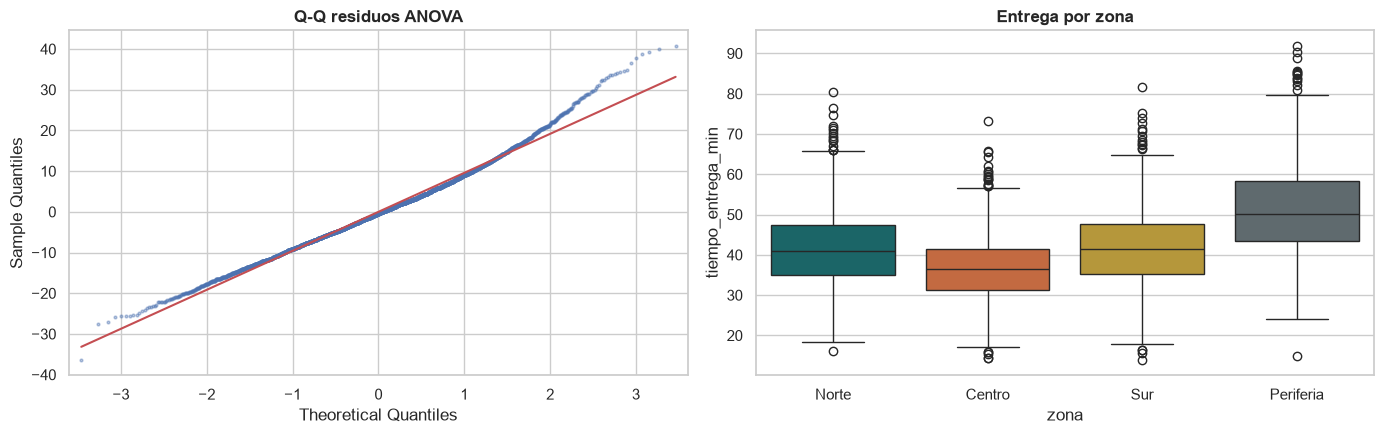

In [37]:
grupos = [df.loc[df["zona"] == z, "tiempo_entrega_min"] for z in ZONAS]
lev_stat, lev_p = stats.levene(*grupos, center="median")
sw_a, sw_a_p = stats.shapiro(m_anova.resid)
jb_a, jb_a_p, sk_a, ku_a = jarque_bera(m_anova.resid)
print(f"Levene (homogeneidad de varianzas): W = {lev_stat:.3f}, p = {lev_p:.2e}")
print(f"Shapiro-Wilk (normalidad de residuos): W = {sw_a:.4f}, p = {sw_a_p:.2e}")
print(f"Jarque-Bera (normalidad de residuos): JB = {jb_a:.2f}, p = {jb_a_p:.2e}  (sesgo = {sk_a:.2f}, curtosis = {ku_a:.2f})")

welch = anova_oneway(df["tiempo_entrega_min"], df["zona"], use_var="unequal")
kw = stats.kruskal(*grupos)
print(f"\nRobustez – ANOVA de Welch (varianzas desiguales): F = {welch.statistic:.2f}, p = {welch.pvalue:.2e}")
print(f"Robustez – Kruskal-Wallis (sin suponer normalidad): H = {kw.statistic:.2f}, p = {kw.pvalue:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sm.qqplot(m_anova.resid, line="s", ax=ax[0], markersize=2, alpha=0.4); ax[0].set_title("Q-Q residuos ANOVA")
sns.boxplot(data=df, x="zona", y="tiempo_entrega_min", order=ZONAS, palette=ZONA_COLORES, hue="zona", legend=False, ax=ax[1])
ax[1].set_title("Entrega por zona")
plt.tight_layout(); plt.show()

**Interpretación.**

- **Levene (W = 27.5, p ≈ 0):** rechazamos H₀. Periferia tiene más dispersión (desv. est. 11.5 min) que Centro (8.2 min): los pedidos largos varían más.
- **Shapiro-Wilk (W = 0.989, p ≈ 0) y Jarque-Bera (p ≈ 0):** rechazamos normalidad, aunque la desviación es moderada (sesgo 0.44, curtosis 3.8) y con más de 700 pedidos por zona el ANOVA es robusto a esto.
- **¿Afecta la conclusión?** Se repitió la prueba con dos métodos que no necesitan esos supuestos. El **ANOVA de Welch** (no supone varianzas iguales; F = 287.3, p ≈ 0) y **Kruskal-Wallis** (no supone normalidad; H = 736.3, p ≈ 0) llegan a la misma decisión. La conclusión de que las zonas difieren en crudo es sólida.

## $\color{#dda}{\text{3.3 Comparaciones por pares: Tukey HSD}}$

Para cada par de zonas: **H₀:** las dos zonas tienen el mismo tiempo medio de entrega. **H₁:** son distintas. Tukey controla que la probabilidad de equivocarse en *alguna* de las 6 comparaciones sea ≤ 5 %.

    Multiple Comparison of Means - Tukey HSD, FWER=0.05    
  group1    group2  meandiff p-adj   lower    upper  reject
-----------------------------------------------------------
   Centro     Norte   4.8536    0.0   3.7572    5.95   True
   Centro Periferia  14.3578    0.0  13.1816 15.5341   True
   Centro       Sur   4.8951    0.0   3.8079  5.9822   True
    Norte Periferia   9.5042    0.0   8.2874 10.7211   True
    Norte       Sur   0.0415 0.9997  -1.0894  1.1724  False
Periferia       Sur  -9.4628    0.0 -10.6712 -8.2543   True
-----------------------------------------------------------


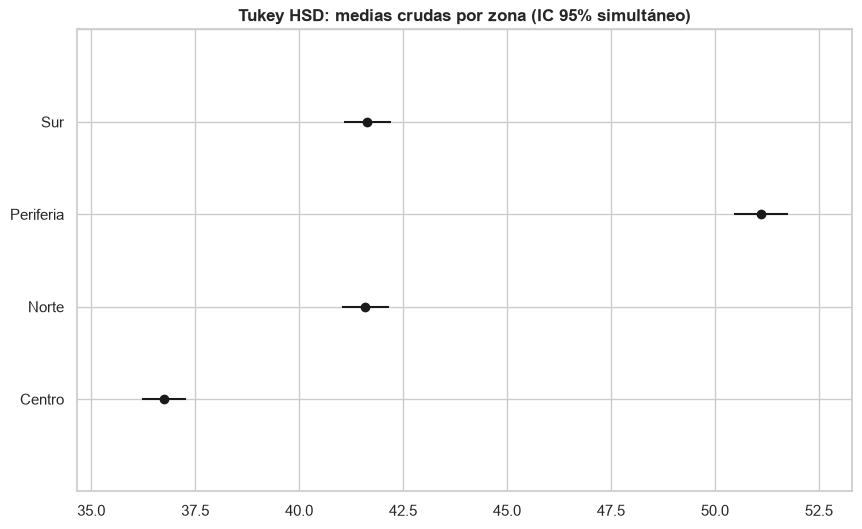

In [38]:
tukey = pairwise_tukeyhsd(df["tiempo_entrega_min"], df["zona"], alpha=ALPHA)
print(tukey)
tukey.plot_simultaneous(); plt.title("Tukey HSD: medias crudas por zona (IC 95% simultáneo)"); plt.show()

**Interpretación.** Cinco de seis pares son distintos (p ajustada ≈ 0). Periferia tarda **14.4 min más que Centro**, 9.5 más que Norte y 9.5 más que Sur. Centro es 4.9 min más rápida que Norte y Sur. **Norte y Sur son iguales** (diferencia de 0.04 min, p = 0.9997). En crudo, el reporte de la Directora es correcto. Tukey supone varianzas iguales (que Levene rechazó), pero las diferencias son mucho mayores que el ancho de los intervalos (~±1.1 min), así que ninguna conclusión depende de ese supuesto.

## $\color{#dda}{\text{3.4 ¿Qué dice el modelo de la Parte 2 sobre las zonas?}}$

El ANOVA compara pedidos de zonas distintas **tal como son**. La regresión de la Parte 2 funciona como un **ANCOVA**: compara las medias de las zonas **ajustando por covariables** (misma distancia, vehículo, clima, franja, carga, experiencia y preparación). Se reestima el modelo de la Parte 2 con toda la base para comparar en igualdad de datos.

In [39]:
# Mismo modelo de la Parte 2, ahora sobre toda la base para comparar en igualdad de condiciones
m_full = smf.ols(f_final, data=df).fit()
zona_coef = m_full.params.filter(like="C(zona")
zona_ci = m_full.conf_int().loc[zona_coef.index]

crudo = df.groupby("zona")["tiempo_entrega_min"].mean() - df.loc[df["zona"] == "Norte", "tiempo_entrega_min"].mean()
ajustado = pd.Series({z: 0.0 for z in ZONAS})
for idx, v in zona_coef.items():
    ajustado[idx.split("[T.")[1].rstrip("]")] = v
comp = pd.DataFrame({"diferencia_cruda_vs_Norte (ANOVA)": crudo.loc[ZONAS],
                     "diferencia_ajustada_vs_Norte (regresión)": ajustado.loc[ZONAS]}).round(2)
print(comp)
print("\nIC 95% de los coeficientes de zona (regresión):")
print(zona_ci.round(2))
print("\nPrueba conjunta de zona dentro de la regresión:")
print(anova_lm(m_full, typ=2).loc[[Z]].round(4))

           diferencia_cruda_vs_Norte (ANOVA)  diferencia_ajustada_vs_Norte (regresión)
Norte                                   0.00                                      0.00
Centro                                 -4.85                                      3.79
Sur                                     0.04                                     -0.17
Periferia                               9.50                                      0.37

IC 95% de los coeficientes de zona (regresión):
                                             0     1
C(zona, Treatment('Norte'))[T.Centro]     3.20  4.38
C(zona, Treatment('Norte'))[T.Periferia] -0.22  0.96
C(zona, Treatment('Norte'))[T.Sur]       -0.66  0.32

Prueba conjunta de zona dentro de la regresión:


                               sum_sq   df        F  PR(>F)
C(zona, Treatment('Norte'))  6238.885  3.0  70.5608     0.0


**Las dos historias son opuestas:**

| Zona | ANOVA (crudo) vs Norte | Regresión (ajustado) vs Norte |
|---|---|---|
| Centro | **−4.9 min** (la más rápida) | **+3.8 min** (la más lenta; IC 3.2 a 4.4) |
| Sur | 0.0 min | −0.2 min (no significativo) |
| Periferia | **+9.5 min** (la más lenta) | **+0.4 min** (no significativo; IC −0.2 a 1.0) |

La zona sigue importando en conjunto dentro de la regresión (F = 70.6, p ≈ 0), pero **solo por Centro**: Periferia, a igualdad de condiciones, no es distinta de Norte.

Para comparar con Tukey sobre la misma base, se repite la comparación por pares sobre el tiempo de entrega *ajustado*: se quita del tiempo de cada pedido lo que explican distancia, vehículo, clima, franja, carga, experiencia y preparación, y se compara lo que queda entre zonas.

In [40]:
# Tukey sobre el tiempo "ajustado": lo que queda del tiempo de entrega después de quitar el efecto
# de distancia, vehículo, clima, franja, carga, experiencia y preparación (residuo del modelo sin zona + media)
m_sin_zona = smf.ols(f_final.replace(f" + {Z}", ""), data=df).fit()
df["entrega_ajustada"] = m_sin_zona.resid + df["tiempo_entrega_min"].mean()
print(df.groupby("zona")["entrega_ajustada"].mean().loc[ZONAS].round(2))
print(pairwise_tukeyhsd(df["entrega_ajustada"], df["zona"], alpha=ALPHA))

zona
Norte        41.14
Centro       43.47
Sur          40.97
Periferia    42.45
Name: entrega_ajustada, dtype: float64


   Multiple Comparison of Means - Tukey HSD, FWER=0.05    
  group1    group2  meandiff p-adj   lower   upper  reject
----------------------------------------------------------
   Centro     Norte  -2.3323    0.0 -2.9582 -1.7063   True
   Centro Periferia  -1.0148 0.0006 -1.6863 -0.3432   True
   Centro       Sur  -2.4974    0.0  -3.118 -1.8767   True
    Norte Periferia   1.3175    0.0  0.6228  2.0122   True
    Norte       Sur  -0.1651  0.913 -0.8107  0.4805  False
Periferia       Sur  -1.4826    0.0 -2.1725 -0.7927   True
----------------------------------------------------------


**Interpretación.** Ya ajustado, el orden se invierte: **Centro es la zona más lenta** (43.5 min), seguida de Periferia (42.5), Norte (41.1) y Sur (41.0). Las diferencias pasan de hasta 14 min a **máximo 2.5 min**. (Esta comparación trata el ajuste como conocido, así que sus p-values son aproximados; la prueba formal es la de los coeficientes de la regresión.)

## $\color{#dda}{\text{3.5 ¿Por qué las dos analíticas cuentan historias distintas?}}$

Porque **las zonas no reciben el mismo tipo de pedidos** (Parte 1). El ANOVA atribuye a la zona todo lo que viene con ella, incluida la distancia. Descomponiendo la brecha cruda de 14.4 min entre Periferia y Centro según el modelo:

In [41]:
# ¿Cuántos minutos de la brecha Periferia − Centro explica cada factor? (contribución = coef x diferencia de medias)
X_full = pd.DataFrame(m_full.model.exog, columns=m_full.model.exog_names)
X_full["zona"] = df["zona"].values
medias_X = X_full.groupby("zona").mean()
contrib = (medias_X.loc["Periferia"] - medias_X.loc["Centro"]) * m_full.params
grupos_c = {
    "Distancia": contrib["distancia_km"],
    "Tipo de vehículo": contrib.filter(like="tipo_vehiculo").sum(),
    "Clima": contrib.filter(like="clima").sum(),
    "Franja horaria": contrib.filter(like="franja").sum(),
    "Carga, experiencia y preparación": contrib[["pedidos_activos_zona", "experiencia_repartidor_meses", "tiempo_preparacion_min"]].sum(),
    "Efecto propio de la zona": contrib.filter(like="C(zona").sum(),
}
dec = pd.Series(grupos_c).round(2)
print(dec.to_string())
print(f"Suma = {dec.sum():.2f} min;  brecha cruda observada = {crudo['Periferia'] - crudo['Centro']:.2f} min")

Distancia                           18.55
Tipo de vehículo                    -1.21
Clima                                0.14
Franja horaria                       0.04
Carga, experiencia y preparación     0.26
Efecto propio de la zona            -3.42
Suma = 14.36 min;  brecha cruda observada = 14.36 min


**Interpretación.**

- La **distancia por sí sola** explicaría que Periferia tardara **18.6 min más** que Centro (7.5 km vs 1.7 km × 3.2 min/km).
- El **vehículo** juega a favor de Periferia (−1.2 min): Centro usa muchas más bicicletas, que son más lentas.
- Clima, franja, carga, experiencia y preparación casi no cambian entre zonas (+0.4 min en total).
- El **efecto propio de la zona** es **−3.4 min**: a igualdad de condiciones, Periferia es *más rápida* que Centro.

Suma: 18.6 − 1.2 + 0.4 − 3.4 = **14.4 min**, exactamente la brecha observada. Es un caso de **variable de confusión**: la distancia está ligada a la zona y al tiempo de entrega, y el ANOVA no la puede separar. Periferia no es lenta por estar mal atendida, sino porque sus clientes viven lejos de los restaurantes. Centro parece rápida porque sus pedidos son cortos, pero por cada pedido comparable es la zona más lenta (probablemente por tráfico, estacionamiento o acceso a edificios, que no están en los datos).

## $\color{#dda}{\text{3.6 Recomendación para la Directora Regional}}$

**No mover repartidores de Centro a Periferia.**

1. **Más repartidores no acortan la distancia.** El tiempo extra de Periferia (≈ 9.5 min vs Norte) se explica por completo por sus 7.5 km promedio. A igual distancia, un pedido de Periferia tarda lo mismo que uno de Norte (+0.4 min, no significativo).
2. **No hay señal de falta de repartidores en Periferia:** los pedidos activos por zona son prácticamente iguales (≈ 11 en todas).
3. **Quitarle repartidores a Centro sería contraproducente:** es la zona con más pedidos (29 % del total) y la más lenta a igualdad de condiciones (+3.8 min vs Norte); con menos repartidores subiría la carga, y cada pedido activo extra suma 0.3 min a todos.
4. **Qué sí haría:** en **Periferia**, asignar motos a pedidos largos, revisar el radio de entrega o sumar restaurantes más cercanos y mostrar estimaciones realistas. En **Centro**, investigar por qué los pedidos comparables tardan ~4 min más (tráfico, estacionamiento, acceso) y evaluar si la bici (+5.3 min vs moto) conviene en todos los pedidos.

---
# $\color{#dda}{\text{Parte 4. Experiencia del Cliente: ¿quién termina con una mala experiencia?}}$

Variable respuesta: `mala_experiencia` = 1 si la calificación es 1 o 2 estrellas (25.4 % de los pedidos).

Experiencia del Cliente tiene **dos objetivos distintos** que requieren **dos modelos** (bitácora #12):

1. **Entender las causas:** se pueden usar todas las variables, incluidas las que ocurren después de la entrega (tiempo de entrega, error en el pedido).
2. **Detectar pedidos en riesgo al momento del pedido:** solo se pueden usar variables conocidas en ese instante. El tiempo de entrega, el error y la calificación **no existen todavía**; un modelo que los usa no se puede poner en producción.

## $\color{#dda}{\text{4.1 Modelo explicativo: ¿qué causa una mala experiencia?}}$

In [42]:
f_log_orden = (f"mala_experiencia ~ distancia_km + pedidos_activos_zona + experiencia_repartidor_meses "
               f"+ tiempo_preparacion_min + monto_pedido_mxn + cliente_nuevo + {Z} + {V} + {F} + {CL}")
f_log_explica = f_log_orden + " + tiempo_entrega_min + pedido_con_error"
lg_explica = smf.logit(f_log_explica, data=train).fit(disp=0)
print(lg_explica.summary())

                           Logit Regression Results                           
Dep. Variable:       mala_experiencia   No. Observations:                 2608
Model:                          Logit   Df Residuals:                     2590
Method:                           MLE   Df Model:                           17
Date:                Fri, 23 Oct 2026   Pseudo R-squ.:                  0.2882
Time:                        12:05:41   Log-Likelihood:                -1048.6
converged:                       True   LL-Null:                       -1473.1
Covariance Type:            nonrobust   LLR p-value:                1.557e-169
                                                       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------
Intercept                                           -8.6281      0.463    -18.626      0.000      -9.536      -7.720
C(zona, Treatment

In [43]:
def tabla_or(modelo):
    ci = modelo.conf_int()
    t = pd.DataFrame({"coef": modelo.params, "OR": np.exp(modelo.params),
                      "OR_IC95_inf": np.exp(ci[0]), "OR_IC95_sup": np.exp(ci[1]), "p": modelo.pvalues})
    t["cambio_en_odds_%"] = (t["OR"] - 1) * 100
    t["decisión"] = np.where(t["p"] < ALPHA, "rechazar H0", "no rechazar H0")
    return t.drop("Intercept").round(4)

tabla_or(lg_explica)

,coef,OR,OR_IC95_inf,OR_IC95_sup,p,cambio_en_odds_%,decisión
"C(zona, Treatment('Norte'))[T.Centro]",0.5930,1.8094,1.1952,2.7392,0.0051,80.9424,rechazar H0
"C(zona, Treatment('Norte'))[T.Periferia]",0.2403,1.2716,0.9088,1.7794,0.1610,27.1631,no rechazar H0
"C(zona, Treatment('Norte'))[T.Sur]",0.2516,1.2861,0.9482,1.7444,0.1057,28.6069,no rechazar H0
"C(tipo_vehiculo, Treatment('Moto'))[T.Auto]",0.0555,1.0570,0.8021,1.3929,0.6937,5.7023,no rechazar H0
"C(tipo_vehiculo, Treatment('Moto'))[T.Bicicleta]",-0.0680,0.9342,0.6661,1.3102,0.6933,-6.5785,no rechazar H0
"C(franja_horaria, Treatment('Mañana'))[T.Comida]",-0.0861,0.9175,0.5850,1.4391,0.7078,-8.2489,no rechazar H0
"C(franja_horaria, Treatment('Mañana'))[T.Noche]",-0.0881,0.9157,0.5975,1.4034,0.6859,-8.4324,no rechazar H0
"C(franja_horaria, Treatment('Mañana'))[T.Tarde]",-0.0516,0.9497,0.6254,1.4421,0.8085,-5.0330,no rechazar H0
"C(clima, Treatment('Despejado'))[T.Lluvia]",0.0873,1.0912,0.8183,1.4552,0.5522,9.1239,no rechazar H0
distancia_km,0.0328,1.0334,0.9453,1.1296,0.4700,3.3354,no rechazar H0


**Prueba global (razón de verosimilitud). H₀:** β₁ = … = βₖ = 0, ningún factor cambia la probabilidad de mala experiencia. **H₁:** al menos un βⱼ ≠ 0. LLR p = 1.6 × 10⁻¹⁶⁹ < 0.05: rechazamos H₀. Pseudo R² de McFadden = 0.29.

**Pruebas de Wald por coeficiente** ($z = \hat\beta / SE(\hat\beta)$). **H₀:** βⱼ = 0, es decir OR = 1 (el factor no cambia los odds de una mala experiencia). **H₁:** βⱼ ≠ 0.

Los coeficientes β están en escala log-odds, $\text{logit}(p) = \ln\frac{p}{1-p}$. Los **odds** comparan la probabilidad de mala experiencia contra la de buena experiencia, $p/(1-p)$ (no contra el total, como la probabilidad). El **odds ratio** $OR = e^{\beta}$ dice por cuánto se multiplican los odds cuando el factor cambia: OR = 1 es el punto neutro, OR = 2 duplica los odds, OR = 0.5 los reduce a la mitad.

**Interpretación.**

- **Tiempo de entrega (OR = 1.154 por minuto, p ≈ 0):** cada minuto extra de entrega aumenta los odds de mala experiencia **15 %**. Diez minutos de retraso lo multiplican por **4.2** (1.154¹⁰).
- **Error en el pedido (OR = 5.80, p ≈ 0):** un artículo faltante o equivocado multiplica los odds de mala experiencia por **5.8**, con el mismo tiempo de entrega.
- **Cliente nuevo (OR = 1.69, p < 0.001):** un cliente en su primer pedido tiene 69 % más odds de calificar mal, con todo lo demás igual. Es más exigente o tiene menos tolerancia.
- **Centro (OR = 1.81 vs Norte, p = 0.005):** con el mismo tiempo de entrega, los clientes de Centro califican peor. Como sus pedidos son cortos, probablemente esperan recibirlos antes.
- **Todo lo demás deja de ser significativo** (distancia, lluvia, vehículo, franja, carga, experiencia, preparación, monto; p > 0.05). Esto no quiere decir que no importen: importan **a través del tiempo de entrega**. La distancia o la lluvia no molestan al cliente por sí mismas, le molesta que el pedido llegue tarde.

**Conclusión causal:** una mala experiencia viene de **llegar tarde** y de **equivocarse en el pedido**, y pesa más en clientes nuevos.

## $\color{#dda}{\text{4.2 Modelo operativo: detectar el riesgo al momento del pedido}}$

Se usan solo variables conocidas al colocar el pedido: distancia, pedidos activos en la zona, experiencia y vehículo del repartidor asignado (bitácora #13), preparación estimada (se muestra al aceptar el pedido), cliente nuevo, zona, franja y clima. Se prueba si el monto aporta algo:

In [44]:
f_log_final = (f"mala_experiencia ~ distancia_km + pedidos_activos_zona + experiencia_repartidor_meses "
               f"+ tiempo_preparacion_min + cliente_nuevo + {Z} + {V} + {F} + {CL}")
lg_completo = smf.logit(f_log_orden, data=train).fit(disp=0)
lg = smf.logit(f_log_final, data=train).fit(disp=0)

# LR parcial: ¿quitar monto_pedido_mxn empeora el modelo?
lr = 2 * (lg_completo.llf - lg.llf)
print(f"LR parcial (monto_pedido_mxn): χ²(1) = {lr:.3f}, p = {stats.chi2.sf(lr, 1):.4f}")
print(lg.summary())

LR parcial (monto_pedido_mxn): χ²(1) = 0.086, p = 0.7693
                           Logit Regression Results                           
Dep. Variable:       mala_experiencia   No. Observations:                 2608
Model:                          Logit   Df Residuals:                     2593
Method:                           MLE   Df Model:                           14
Date:                Fri, 23 Oct 2026   Pseudo R-squ.:                  0.1999
Time:                        12:05:41   Log-Likelihood:                -1178.7
converged:                       True   LL-Null:                       -1473.1
Covariance Type:            nonrobust   LLR p-value:                1.212e-116
                                                       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------
Intercept                                           -6.3132      0.374    -16

In [45]:
pseudo_r2 = 1 - lg.llf / lg.llnull
print(f"Prueba de razón de verosimilitud (modelo global): G = {lg.llr:.2f}, gl = {int(lg.df_model)}, p = {lg.llr_pvalue:.2e}")
print("Decisión:", "rechazar H0" if lg.llr_pvalue < ALPHA else "no rechazar H0")
print(f"Pseudo R² de McFadden: {pseudo_r2:.3f}")

# Prueba conjunta por variable categórica (Wald)
for nombre, term in [("zona", Z), ("tipo_vehiculo", V), ("franja_horaria", F)]:
    R = np.eye(len(lg.params))[lg.params.index.str.startswith(term)]
    w = lg.wald_test(R, scalar=True)
    print(f"Wald conjunto {nombre}: χ² = {w.statistic:.2f}, p = {w.pvalue:.4f}")

Prueba de razón de verosimilitud (modelo global): G = 588.92, gl = 14, p = 1.21e-116
Decisión: rechazar H0
Pseudo R² de McFadden: 0.200
Wald conjunto zona: χ² = 29.64, p = 0.0000
Wald conjunto tipo_vehiculo: χ² = 17.44, p = 0.0002
Wald conjunto franja_horaria: χ² = 5.75, p = 0.1245


**Pruebas.**

- **LR parcial del monto. H₀:** el monto del pedido no cambia la probabilidad de mala experiencia. χ²(1) = 0.09, p = 0.77: no rechazamos H₀. Se quita (bitácora #15).
- **Prueba global de razón de verosimilitud. H₀:** ninguna de las variables disponibles al pedir cambia la probabilidad de mala experiencia. **H₁:** al menos una sí. G = 588.9 con 14 gl, p = 1.2 × 10⁻¹¹⁶ < 0.05: **rechazamos H₀**. Con información disponible al hacer el pedido **sí se puede anticipar** quién va a tener una mala experiencia.
- **Pseudo R² de McFadden = 0.20:** $R^2 = \frac{LL(base) - LL(fit)}{LL(base)}$. No es "proporción de varianza explicada" como en MCO, sino la mejora relativa de la log-verosimilitud del modelo frente a usar solo la probabilidad global (25 %). En logística, valores entre 0.2 y 0.4 se consideran buen ajuste. Es menor que el 0.29 del modelo explicativo, como se esperaba: no conocemos el tiempo de entrega ni los errores.
- **Wald conjunto por variable categórica. H₀:** todos los niveles de la variable tienen el mismo riesgo que la referencia. Zona (χ² = 29.6, p ≈ 0) y vehículo (χ² = 17.4, p < 0.001): rechazamos H₀. Franja horaria (χ² = 5.75, p = 0.12): no rechazamos H₀; se mantiene por la razón de la bitácora #15.

## $\color{#dda}{\text{4.3 Odds ratios del modelo operativo}}$

In [46]:
tabla_or(lg)

,coef,OR,OR_IC95_inf,OR_IC95_sup,p,cambio_en_odds_%,decisión
"C(zona, Treatment('Norte'))[T.Centro]",1.0091,2.7430,1.8750,4.0129,0.0000,174.3043,rechazar H0
"C(zona, Treatment('Norte'))[T.Periferia]",0.2952,1.3434,0.9803,1.8411,0.0664,34.3433,no rechazar H0
"C(zona, Treatment('Norte'))[T.Sur]",0.2316,1.2606,0.9484,1.6754,0.1107,26.0571,no rechazar H0
"C(tipo_vehiculo, Treatment('Moto'))[T.Auto]",0.3947,1.4839,1.1496,1.9153,0.0024,48.3898,rechazar H0
"C(tipo_vehiculo, Treatment('Moto'))[T.Bicicleta]",0.5231,1.6873,1.2455,2.2860,0.0007,68.7332,rechazar H0
"C(franja_horaria, Treatment('Mañana'))[T.Comida]",0.4110,1.5083,0.9971,2.2817,0.0517,50.8309,no rechazar H0
"C(franja_horaria, Treatment('Mañana'))[T.Noche]",0.2306,1.2593,0.8484,1.8691,0.2525,25.9294,no rechazar H0
"C(franja_horaria, Treatment('Mañana'))[T.Tarde]",0.0461,1.0472,0.7113,1.5419,0.8151,4.7227,no rechazar H0
"C(clima, Treatment('Despejado'))[T.Lluvia]",0.9430,2.5676,2.0368,3.2367,0.0000,156.7608,rechazar H0
distancia_km,0.4308,1.5384,1.4453,1.6376,0.0000,53.8446,rechazar H0


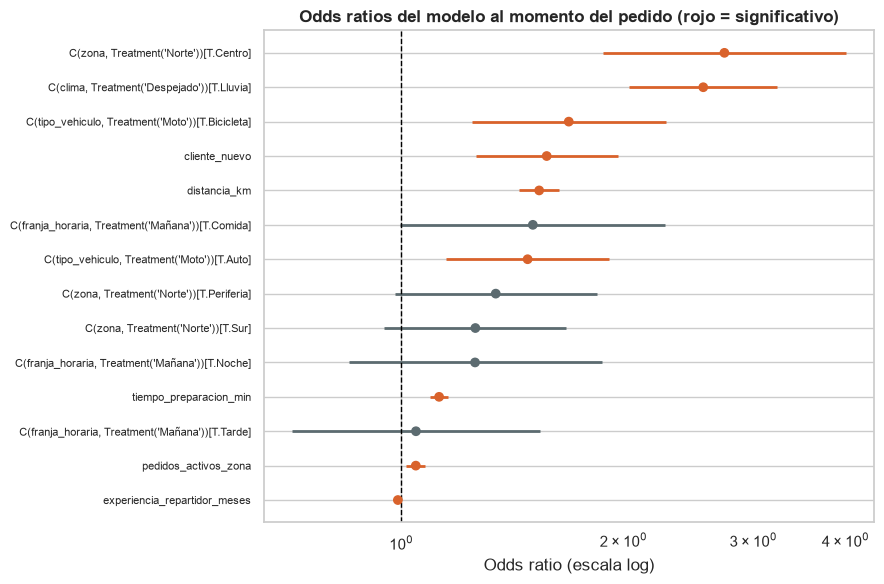

+1 km de distancia:          OR = 1.538
+5 km de distancia:          OR = 8.618
+5 min de preparación:       OR = 1.808
+5 pedidos activos en zona:  OR = 1.256
+12 meses de experiencia:    OR = 0.883


In [47]:
t = tabla_or(lg).sort_values("OR")
fig, ax = plt.subplots(figsize=(9, 6))
colores = np.where(t["p"] < ALPHA, CORAL, GREY)
ax.errorbar(t["OR"], range(len(t)), xerr=[t["OR"] - t["OR_IC95_inf"], t["OR_IC95_sup"] - t["OR"]],
            fmt="none", ecolor=colores, elinewidth=2)
ax.scatter(t["OR"], range(len(t)), color=colores, zorder=3)
ax.axvline(1, color="black", lw=1, ls="--")
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index, fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("Odds ratio (escala log)")
ax.set_title("Odds ratios del modelo al momento del pedido (rojo = significativo)")
plt.tight_layout(); plt.show()

# Odds ratios para cambios con sentido de negocio
print(f"+1 km de distancia:          OR = {np.exp(lg.params['distancia_km']):.3f}")
print(f"+5 km de distancia:          OR = {np.exp(5 * lg.params['distancia_km']):.3f}")
print(f"+5 min de preparación:       OR = {np.exp(5 * lg.params['tiempo_preparacion_min']):.3f}")
print(f"+5 pedidos activos en zona:  OR = {np.exp(5 * lg.params['pedidos_activos_zona']):.3f}")
print(f"+12 meses de experiencia:    OR = {np.exp(12 * lg.params['experiencia_repartidor_meses']):.3f}")

**Interpretación (cada OR manteniendo lo demás constante; H₀: OR = 1 en cada caso).**

| Factor | OR | IC 95 % | p | Lectura de negocio |
|---|---|---|---|---|
| Distancia | **1.54 por km** | 1.45 a 1.64 | ≈ 0 | Cada km extra aumenta los odds de mala experiencia **54 %**. Un pedido 5 km más lejos tiene **8.6 veces** los odds. |
| Lluvia (vs Despejado) | **2.57** | 2.04 a 3.24 | ≈ 0 | Pedir con lluvia multiplica los odds por 2.6 (+157 %). |
| Centro (vs Norte) | **2.74** | 1.88 a 4.01 | ≈ 0 | A igual distancia, un pedido en Centro tiene 2.7 veces los odds. Combina que Centro es más lenta a igualdad de condiciones (Parte 3) y que sus clientes son más exigentes (4.1). |
| Periferia (vs Norte) | 1.34 | 0.98 a 1.84 | 0.066 | No significativo: una vez considerada la distancia, Periferia no es más riesgosa que Norte. |
| Sur (vs Norte) | 1.26 | 0.95 a 1.68 | 0.11 | No significativo. |
| Bicicleta (vs Moto) | **1.69** | 1.25 a 2.29 | < 0.001 | +69 % de odds, coherente con los +5.3 min de la Parte 2. |
| Auto (vs Moto) | **1.48** | 1.15 a 1.92 | 0.002 | +48 % de odds (+3 min en la Parte 2). |
| Preparación | **1.126 por min** | 1.10 a 1.16 | ≈ 0 | Cada minuto de cocina suma 12.6 % a los odds; 5 min más, ×1.81. |
| Cliente nuevo | **1.58** | 1.26 a 1.97 | < 0.001 | Un cliente en su primer pedido tiene 58 % más odds de calificar mal. |
| Pedidos activos en la zona | **1.047 por pedido** | 1.02 a 1.08 | 0.003 | 5 pedidos activos más: ×1.26 (+26 %). |
| Experiencia del repartidor | **0.990 por mes** | 0.984 a 0.996 | < 0.001 | Cada año de experiencia reduce los odds **12 %** (OR = 0.88 por 12 meses). |
| Comida (vs Mañana) | 1.51 | 1.00 a 2.28 | 0.052 | En el límite; no significativo al 5 %. |
| Noche, Tarde (vs Mañana) | 1.26, 1.05 | incluyen 1 | > 0.25 | No significativos. |

**Conexión con las Partes 2 y 3:** los factores de riesgo al pedir son, casi uno a uno, los que alargan la entrega en la Parte 2 (distancia, lluvia, bici/auto, preparación, saturación, poca experiencia, Centro). Esto confirma lo que dijo el modelo explicativo: el riesgo viene del retraso. El único factor que no pasa por el tiempo es el **cliente nuevo**.

## $\color{#dda}{\text{4.4 Supuestos de la regresión logística}}$

In [48]:
# 1) Multicolinealidad
Xl = pd.DataFrame(lg.model.exog, columns=lg.model.exog_names)
vif_l = pd.Series([variance_inflation_factor(Xl.values, i) for i in range(Xl.shape[1])], index=Xl.columns).drop("Intercept")
print(f"VIF máximo: {vif_l.max():.2f} ({vif_l.idxmax()})")

# 2) Linealidad en el logit (Box-Tidwell): se agrega x·ln(x) para cada continua; si es significativo, no es lineal
cont_l = ["distancia_km", "pedidos_activos_zona", "experiencia_repartidor_meses", "tiempo_preparacion_min"]
bt = train.copy()
for c in cont_l:
    bt[f"{c}_ln"] = bt[c] * np.log(bt[c])
lg_bt = smf.logit(f_log_final + " + " + " + ".join(f"{c}_ln" for c in cont_l), data=bt).fit(disp=0)
print("\nBox-Tidwell (p de cada término x·ln x):")
print(lg_bt.pvalues[[f"{c}_ln" for c in cont_l]].round(4).to_string())

# 3) Tamaño de muestra: eventos por parámetro
eventos = train["mala_experiencia"].sum()
print(f"\nEventos (malas experiencias) en entrenamiento: {eventos};  parámetros: {int(lg.df_model)};  "
      f"eventos por parámetro: {eventos / lg.df_model:.0f}")

VIF máximo: 3.52 (C(franja_horaria, Treatment('Mañana'))[T.Comida])

Box-Tidwell (p de cada término x·ln x):
distancia_km_ln                    0.7431
pedidos_activos_zona_ln            0.3745
experiencia_repartidor_meses_ln    0.0673
tiempo_preparacion_min_ln          0.9802

Eventos (malas experiencias) en entrenamiento: 658;  parámetros: 14;  eventos por parámetro: 47


**Interpretación.**

- **Variable respuesta binaria:** sí (mala / no mala).
- **Independencia de observaciones:** una fila por pedido. Limitación: no tenemos `id_cliente`, así que no podemos verificar si un mismo cliente aparece varias veces.
- **Multicolinealidad:** VIF máximo 3.5 (< 5): los efectos se pueden separar.
- **Linealidad en el logit (Box-Tidwell). H₀:** cada variable continua tiene una relación lineal con el log-odds. **H₁:** no es lineal. Todas tienen p > 0.05 (distancia 0.74, pedidos activos 0.37, preparación 0.98; experiencia 0.067, en el límite). No rechazamos H₀: los OR "por unidad" son válidos en todo el rango.
- **Tamaño de muestra:** 658 eventos para 14 parámetros = 47 eventos por parámetro, muy por arriba de la regla mínima de 10. Los coeficientes son estables.
- **Sin separación perfecta:** el modelo converge y los errores estándar son razonables.

## $\color{#dda}{\text{4.5 Desempeño en pedidos no vistos}}$

In [49]:
y_te = test["mala_experiencia"]
proba = lg.predict(test)

def metricas_clf(y, p, umbral):
    pred = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return pd.Series({"umbral": umbral, "sensitivity (recall)": recall_score(y, pred), "specificity": tn / (tn + fp),
                      "precision": precision_score(y, pred), "negative predicted value": tn / (tn + fn),
                      "accuracy": accuracy_score(y, pred), "F1": f1_score(y, pred),
                      "TP": tp, "FN (error tipo II)": fn, "FP (error tipo I)": fp, "TN": tn,
                      "% pedidos con cupón": pred.mean()})

fpr, tpr, umbrales = roc_curve(y_te, proba)
auc_test = auc(fpr, tpr)
youden = umbrales[np.argmax(tpr - fpr)]
print(f"AUC en prueba: {auc_test:.3f}   (entrenamiento: {auc(*roc_curve(train['mala_experiencia'], lg.predict(train))[:2]):.3f})")
print(f"Umbral de Youden (max sensibilidad + especificidad − 1): {youden:.3f}")
print(f"Tasa base de mala experiencia en prueba: {y_te.mean():.1%}")
pd.DataFrame({"umbral 0.50": metricas_clf(y_te, proba, 0.5),
              "umbral Youden": metricas_clf(y_te, proba, youden)}).round(3)

AUC en prueba: 0.772   (entrenamiento: 0.790)
Umbral de Youden (max sensibilidad + especificidad − 1): 0.286
Tasa base de mala experiencia en prueba: 25.8%


,umbral 0.50,umbral Youden
umbral,0.500,0.286
sensitivity (recall),0.319,0.615
specificity,0.931,0.776
precision,0.617,0.488
negative predicted value,0.798,0.853
accuracy,0.774,0.734
F1,0.421,0.544
TP,92.000,177.000
FN (error tipo II),196.000,111.000
FP (error tipo I),57.000,186.000


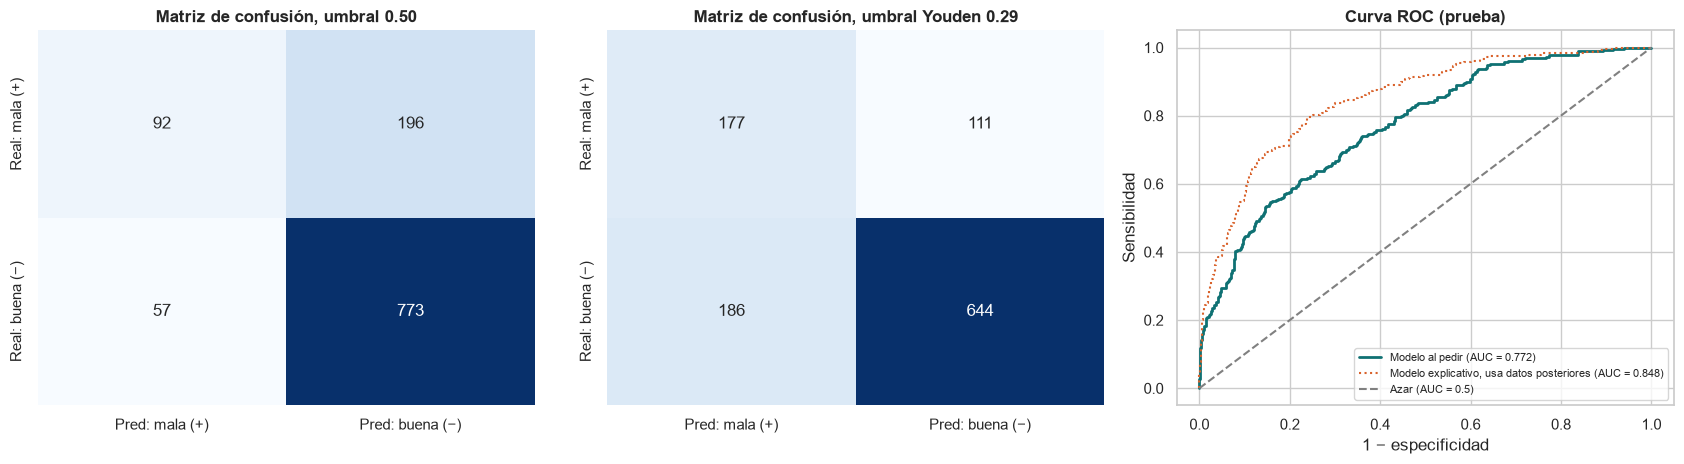

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (nombre, u) in zip(axes[:2], [("0.50", 0.5), (f"Youden {youden:.2f}", youden)]):
    cm = confusion_matrix(y_te, (proba >= u).astype(int), labels=[1, 0])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred: mala (+)", "Pred: buena (−)"], yticklabels=["Real: mala (+)", "Real: buena (−)"])
    ax.set_title(f"Matriz de confusión, umbral {nombre}")
axes[2].plot(fpr, tpr, color=TEAL, lw=2, label=f"Modelo al pedir (AUC = {auc_test:.3f})")
fpr_e, tpr_e, _ = roc_curve(y_te, lg_explica.predict(test))
axes[2].plot(fpr_e, tpr_e, color=CORAL, lw=1.5, ls=":", label=f"Modelo explicativo, usa datos posteriores (AUC = {auc(fpr_e, tpr_e):.3f})")
axes[2].plot([0, 1], [0, 1], color="gray", ls="--", label="Azar (AUC = 0.5)")
axes[2].set_xlabel("1 − especificidad"); axes[2].set_ylabel("Sensibilidad"); axes[2].set_title("Curva ROC (prueba)")
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretación de cada métrica (1,118 pedidos de prueba, 25.8 % con mala experiencia).** Positivo = mala experiencia. Un **falso negativo (error tipo II)** es una mala experiencia que el modelo no detecta (cliente sin cupón que se va); un **falso positivo (error tipo I)** es un cupón que se manda a un pedido que iba a salir bien.

- **AUC = 0.772:** si tomamos al azar un pedido que terminó mal y uno que terminó bien, en **77 % de los casos** el modelo le da más riesgo al que terminó mal (0.5 = azar, 1 = perfecto). En entrenamiento fue 0.790: caída pequeña, sin sobreajuste importante. El modelo explicativo (línea punteada) llega más alto, pero usa información que no existe al pedir; el modelo operativo es el que sí se puede usar.

Con el **umbral de 0.50** (cupón si la probabilidad es ≥ 50 %):
- **Exactitud (accuracy) 77.4 %:** acierta en 3 de cada 4 pedidos, pero decirle "buena" a todos ya daría 74.2 %. Engaña.
- **Precisión 61.7 %:** de los pedidos que reciben cupón, 6 de cada 10 terminan mal.
- **Sensibilidad (recall) 31.9 %:** solo detecta **1 de cada 3** malas experiencias. Se le escapan 196.
- **Especificidad 93.1 %:** casi no le da cupón a quien no lo necesita.
- **Valor predictivo negativo 79.8 %:** de los pedidos sin cupón, 8 de cada 10 sí terminan bien.
- **F1 = 0.42:** balance pobre entre precisión y sensibilidad.

Con el **umbral de Youden 0.29** (maximiza sensibilidad + especificidad):
- **Sensibilidad 61.5 %:** detecta **6 de cada 10** malas experiencias (177 de 288).
- **Precisión 48.8 %:** la mitad de los cupones llegan a pedidos que sí terminan mal (vs 25.8 % si se repartieran al azar: casi el doble de efectivo).
- **Especificidad 77.6 %:** 22 % de los pedidos buenos reciben un cupón "de más".
- **Valor predictivo negativo 85.3 %:** de los pedidos sin cupón, 85 % terminan bien; solo 15 % de los que se quedan sin cupón califican mal.
- **Exactitud 73.4 %** y **F1 = 0.54:** mejor balance que con 0.50.
- **Costo:** se manda cupón a **32.5 %** de los pedidos.

Como el objetivo es no perder clientes, el error caro es el **tipo II** (no detectar una mala experiencia), no el tipo I (regalar un cupón de más). Por eso recomiendo 0.29 sobre 0.50.

In [51]:
# ¿Qué tan concentrado está el riesgo? Pedidos de prueba ordenados por probabilidad predicha
dec = pd.qcut(proba.rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = y_te.groupby(dec, observed=True).agg(["count", "mean"]).sort_index()
lift["% mala exp"] = (lift["mean"] * 100).round(1)
lift["% de todas las malas capturadas (acum.)"] = (y_te.groupby(dec, observed=True).sum().sort_index().cumsum() / y_te.sum() * 100).round(1)
lift.drop(columns="mean").rename_axis("decil de riesgo (1 = más riesgoso)")

,count,% mala exp,% de todas las malas capturadas (acum.)
decil de riesgo (1 = más riesgoso),,,
1,112,68.8,26.7
2,112,49.1,45.8
3,112,32.1,58.3
4,111,22.5,67.0
5,112,23.2,76.0
6,112,20.5,84.0
7,111,25.2,93.8
8,112,8.0,96.9
9,112,5.4,99.0


**Interpretación.** Si el presupuesto de cupones es limitado, el riesgo está muy concentrado: el **10 % de pedidos más riesgosos** termina mal **69 %** de las veces, y el **20 % más riesgoso** concentra **46 %** de todas las malas experiencias con una tasa de ~59 %. En cambio, el 30 % de menor riesgo casi nunca termina mal (2.7–8 %).

## $\color{#dda}{\text{4.6 Respuesta para Experiencia del Cliente}}$

- **Qué causa una mala experiencia:** **llegar tarde** (cada minuto extra sube los odds 15 %; 10 min de retraso los multiplican por 4) y **equivocarse en el pedido** (×5.8). Los **clientes nuevos** son más exigentes (×1.7). Lo demás (distancia, lluvia, vehículo) importa porque retrasa la entrega.
- **Cómo detectar pedidos en riesgo al momento del pedido:** con el modelo operativo, que usa solo distancia, clima, zona, vehículo, preparación, carga, experiencia del repartidor y si el cliente es nuevo. Distingue bien (AUC 0.77) en pedidos que nunca vio.
- **Regla recomendada:** mandar cupón cuando el riesgo estimado sea ≥ **29 %**. Le llega a ~1 de cada 3 pedidos, detecta 6 de cada 10 malas experiencias y la mitad de los cupones llegan a quien sí los necesita. Con poco presupuesto: cupón solo al 20 % más riesgoso (detecta 46 % de las malas experiencias, 59 % de acierto).
- **Más allá del cupón:** el cupón compensa, pero no evita. Para los pedidos marcados conviene también **asignar moto y repartidores experimentados** y **avisar un tiempo realista**. Los errores en el pedido no se pueden anticipar con estos datos, así que se atacan en el restaurante (revisión de empaque), no con el modelo.

---
# $\color{#dda}{\text{Parte 5. Memo ejecutivo}}$

**Para:** Director(a) de Operaciones (COO), RapidoMX  ·  **De:** Equipo de Analítica  ·  **Asunto:** Respuestas para la planeación del trimestre

Antes de contestar tuve que limpiar la base, porque venía directo del sistema: de 4,080 registros quedaron 3,726 pedidos confiables (había pedidos duplicados, tiempos de entrega imposibles como 0 o 999 minutos y registros sin clima o sin la experiencia del repartidor). Todo lo que sigue sale de esos pedidos.

**1. Operaciones, qué hace lenta una entrega:**
Lo que más pesa es la distancia, cada kilómetro agrega **3.2 minutos**, y después vienen la lluvia (**casi 6 minutos** más), la bicicleta (**5 minutos** más que la moto; el auto, 3), la hora de la comida (**4 minutos** más que en la mañana) y la cocina del restaurante, porque cada minuto de preparación se vuelve 0.8 minutos de entrega. De todo eso RapidoMX sí puede mover el vehículo que asigna, la presión sobre los restaurantes lentos, la saturación de cada zona (10 pedidos activos de más le cuestan 3 minutos a todos) y la retención de repartidores, ya que dos años de experiencia ahorran 2 minutos por pedido. Probé el modelo con pedidos que nunca había visto y se equivoca en promedio por **4 minutos**, así que creo que ya sirve para el tiempo que se le muestra al cliente en la app, siempre que se muestre como un rango y no como un número exacto: **más o menos 8 minutos con cielo despejado y más o menos 16 con lluvia** (la lluvia no solo retrasa, también vuelve la entrega el doble de impredecible).

**2. Dirección Regional, si hay zonas peores:**
Es cierto que en promedio Periferia tarda 51 minutos y Centro 37, pero un pedido de Periferia recorre **7.5 km** y uno de Centro apenas **1.7 km**. Cuando se comparan pedidos iguales (misma distancia, vehículo, clima y hora), Periferia tarda lo mismo que Norte y Sur, y Centro resulta la zona más lenta, con **4 minutos** más. Es decir, la diferencia de Periferia es casi toda distancia, y la distancia no se acorta con más repartidores. Por eso recomiendo **no mover repartidores de Centro a Periferia**: Centro concentra el 29 % de los pedidos y con menos gente la saturación le subiría el tiempo a todos sus clientes. Para Periferia creo que sería más útil asignar motos a los pedidos largos, sumar restaurantes cercanos o, de ser necesario, acortar el radio de entrega.

**3. Experiencia del Cliente, quién termina con una mala experiencia:**
Una de cada cuatro entregas recibe 1 o 2 estrellas, y la causa principal es llegar tarde: **10 minutos de retraso multiplican por 4 las chances de una mala calificación (los odds comparan la probabilidad de que el pedido salga mal contra la de que salga bien). Un artículo faltante o equivocado **los multiplica por 6**, y los clientes nuevos son más exigentes que los recurrentes. Ni el retraso ni el error se conocen cuando se hace el pedido, pero sí lo que los anticipa (distancia, clima, zona, vehículo, tiempo de cocina y si el cliente es nuevo), así que propongo **mandar el cupón cuando el riesgo estimado llegue a 29 % o más**. Eso le da cupón a uno de cada tres pedidos y alcanza a **6 de cada 10 malas experiencias**, con la mitad de los cupones cayendo en quien sí lo necesitaba (el doble que si se repartieran al azar). En el peor de los casos, si el presupuesto no alcanza, dárselo solo al 20 % más riesgoso debería bastar para cubrir casi la mitad de las malas experiencias. A esos mismos pedidos conviene asignarles moto y repartidores con experiencia [punto 1], porque el cupón compensa el mal rato pero no lo evita.

**Limitaciones:**
La base no trae fecha y hora, ni cuántos repartidores había por zona, ni un identificador de cliente, así que la falta de repartidores no se pudo medir directamente (solo la saturación de pedidos, que es parecida en las cuatro zonas). Además, los resultados muestran relaciones y no salen de un experimento, por lo que cualquier cambio (reasignar vehículos, por ejemplo) debería probarse primero en un piloto. Supuse también que el repartidor se asigna al aceptar el pedido; si se asigna después, el cupón tendría que mandarse en ese momento.